In [1]:
from pathlib import Path
from copy import deepcopy
from unittest.mock import patch
from io import BytesIO
import sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

PROJECT = Path("..").resolve()
sys.path.insert(0, str(PROJECT))
from src import parallel_blocks_v2 as local
from src import remote_parallel_blocks as remote
import icesat2db as isdb
from sliderule import sliderule

CONFIG_PATH = PROJECT / "config.yaml"
CAMERAS_PATH = Path("../../Chapter_1/snow_cam_details.xlsx")
DATA_ROOT = Path("../../data_store/ICESat-2")
SITES = ["sodankyla_full", "delta_junction", "marcell_MN", "lacclair"]       # Folder names; None = all cameras with local data.
PAIR_INDICES = None             # e.g. [0, 3, 8], from the table below.
MAX_OVERPASSES = None             # None = all selected pairs.
LENGTH_M = 30                   # Use the same resolution in both pipelines.
ROI_HALF_KM = 4                 # 8 x 8 km, matching generate_dataframe's default.
MSW_MAX = 6.0                   # Maximum beam-mean flag; increase if needed.
LAYER_MAX = 1.1
AXIS_MAX = 9                   # Includes <16 radiometry after Beam 3's correction.

In [2]:
with CONFIG_PATH.open() as stream:
    cfg = yaml.safe_load(stream)
q = cfg["parallel_blocks"]
q.update(roi_half_width=ROI_HALF_KM, roi_half_height=ROI_HALF_KM,
         small_box_half_side=None, rebinned=LENGTH_M,
         msw_flag_threshold=MSW_MAX, layer_flag_threshold=LAYER_MAX,
         trim_atmospheric=True)
q.update(
    insufficient_data_threshold=3,
    alt_thresh=80,
    # outlier_removal=None,
    loss="linear",
    f_scale=0.05,
    landcover="forest",
    trim_atmospheric=True,
    sat_flag=True,
)
# None is the local code's full-ROI mode; a numeric small_box can recentre boxes.
# Both use ATL08 landcover, the camera altitude, and the remaining YAML filters.

cameras = pd.read_excel(CAMERAS_PATH)
cameras["Date"] = pd.to_datetime(cameras.Date).dt.normalize()
pattern = re.compile(r"(ATL0[38])_(\d{14})_(\d{8})_(\d{3})_(\d{2}).*\.h5$")
rows = []
for site in (SITES if SITES is not None else cameras.Camera.dropna().unique()):
    directory = DATA_ROOT / site
    if not directory.is_dir():
        print(f"No local directory: {directory}")
        continue
    files = [(p.resolve(), pattern.search(p.name)) for p in sorted(directory.glob("*.h5"))]
    files = [(p, m) for p, m in files if m]
    for a, m in files:
        if m[1] != "ATL03":
            continue
        matches = [b for b, k in files if k[1] == "ATL08"
                   and k.group(2, 3, 4) == m.group(2, 3, 4)
                   and b.name.startswith("processed_") == a.name.startswith("processed_")]
        if len(matches) != 1:
            print(f"Skipped {a.name}: {len(matches)} matching ATL08 files")
            continue
        if m[4] != "007":
            print(f"Skipped {a.name}: remote database is release 007")
            continue
        date = pd.to_datetime(m[2], format="%Y%m%d%H%M%S").normalize()
        camera = cameras.loc[cameras.Camera.eq(site) & cameras.Date.eq(date),
                             ["x_coord", "y_coord", "Altitude"]].drop_duplicates()
        if len(camera) != 1 or camera.isna().any().any():
            print(f"Skipped {site} {date.date()}: missing/ambiguous camera metadata")
            continue
        lon, lat, altitude = camera.iloc[0]
        rows.append(dict(site=site, date=date, longitude=lon, latitude=lat,
                         altitude=altitude, atl03=a, atl08=matches[0],
                         resource=f"ATL03_{m[2]}_{m[3]}_{m[4]}_{m[5]}.h5"))
pairs = pd.DataFrame(rows)
if pairs.empty:
    raise ValueError("No matching pairs. Check DATA_ROOT, SITES and CAMERAS_PATH.")
pairs = pairs.sort_values(["site", "resource"]).reset_index(drop=True)
display(pairs[["site", "date", "resource", "altitude"]])

Skipped ATL03_20191213054709_11810505_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20221006044133_02361705_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20231216191349_13562103_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250303104135_11812605_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250314213142_13562603_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250401091723_02362705_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250412200737_04112703_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250602062054_11812705_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250613171107_13562703_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250701045653_02362805_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250712154650_04112803_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20200212141633_07310605_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250503191056_07312705_007_01.h5: 0 matching ATL08 files
Skipped ATL03_20250625041132_01442803_007_01.h5: 0 matching ATL0

,site,date,resource,altitude
0,delta_junction,2018-11-05,ATL03_20181105235511_05860103_007_01.h5,504.0
1,delta_junction,2018-11-15,ATL03_20181115115748_07310105_007_01.h5,504.0
2,delta_junction,2019-02-04,ATL03_20190204193503_05860203_007_01.h5,504.0
3,delta_junction,2019-02-14,ATL03_20190214073734_07310205_007_01.h5,504.0
4,delta_junction,2019-04-07,ATL03_20190407163842_01440303_007_01.h5,504.0
...,...,...,...,...
248,sodankyla_full,2024-10-01,ATL03_20241001175816_02362505_007_01.h5,179.0
249,sodankyla_full,2024-10-13,ATL03_20241013044838_04112503_007_01.h5,179.0
250,sodankyla_full,2024-12-14,ATL03_20241214015156_13562503_007_01.h5,179.0
251,sodankyla_full,2024-12-31,ATL03_20241231133747_02362605_007_01.h5,179.0


In [3]:
import logging
logging.disable(logging.WARNING)  # Suppress INFO and WARNING; keep ERROR messages.

def capture_plot(call):
    """Keep the pipeline's own scatter, outliers and fitted lines."""
    before = set(plt.get_fignums())
    figures = []
    def collect(*args, **kwargs):
        for number in set(plt.get_fignums()) - before:
            fig = plt.figure(number)
            if fig not in figures:
                figures.append(fig)
    try:
        with plt.ioff(), patch.object(plt, "show", collect):
            result = call()
            collect()
    except Exception:
        for number in set(plt.get_fignums()) - before:
            plt.close(number)
        raise
    if len(figures) > 1:
        for fig in figures:
            plt.close(fig)
        raise RuntimeError("Pipeline produced multiple plots: check full-ROI mode.")
    return result, figures[0] if figures else None


def plot_image(fig):
    # Standardise both original plots before composing the comparison.
    fig.set_size_inches(7, 5.5)
    if fig._suptitle is not None:
        fig._suptitle.set_text("")
    for ax in fig.axes:
        ax.set(xlim=(0, AXIS_MAX), ylim=(0, AXIS_MAX))
    fig.tight_layout()
    stream = BytesIO()
    fig.savefig(stream, format="png", dpi=150)
    stream.seek(0)
    pixels = plt.imread(stream)
    plt.close(fig)
    return pixels

provider = isdb.IceSat2Provider(
    storage_type="s3", s3_bucket="dog-ext.icesat2db.icesat2-atl08-v007",
    url="https://s3.gfz.de")
sliderule.init(verbose=False, rethrow=True)

True


0: delta_junction | ATL03_20181105235511_05860103_007_01.h5
Nothing to rebin for delta_junction file 0's beam 3.
Nothing to rebin for delta_junction file 0's beam 4.
Failed to open ATL03 file for delta_junction file 0's beam 5.
Failed to open ATL03 file for delta_junction file 0's beam 6.
delta_junction: 1 overpasses
  ATL03_20181105235511_05860103_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,70907.0,270.0,7.0,7.0
1,gt1r,ok,142714.0,269.0,61.0,58.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


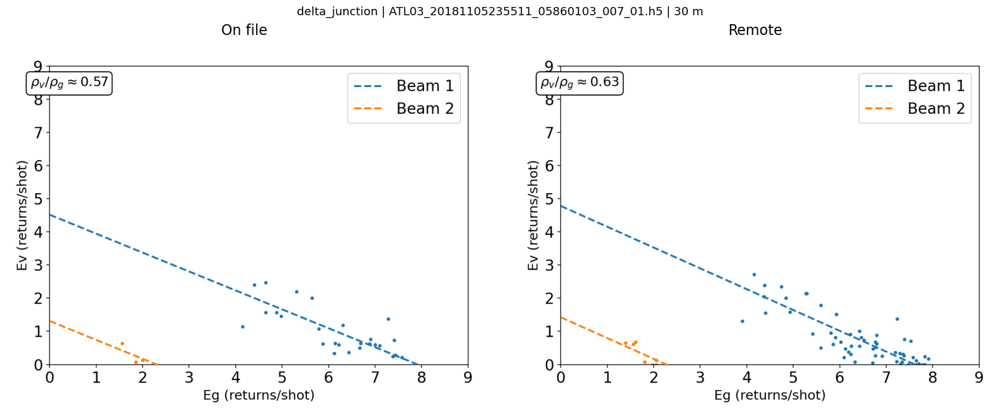


1: delta_junction | ATL03_20181115115748_07310105_007_01.h5
Beam 1 in delta_junction file 1 has no data after filtering.
Beam 2 in delta_junction file 1 has no data after filtering.
Beam 3 in delta_junction file 1 has no data after filtering.
Beam 4 in delta_junction file 1 has no data after filtering.
Nothing to rebin for delta_junction file 1's beam 5.
Nothing to rebin for delta_junction file 1's beam 6.
delta_junction: 1 overpasses
  ATL03_20181115115748_07310105_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,ok,42307.0,269.0,57.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,ok,22021.0,269.0,17.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



2: delta_junction | ATL03_20190204193503_05860203_007_01.h5
Nothing to rebin for delta_junction file 2's beam 1.
Nothing to rebin for delta_junction file 2's beam 2.
Nothing to rebin for delta_junction file 2's beam 3.
Nothing to rebin for delta_junction file 2's beam 4.
Nothing to rebin for delta_junction file 2's beam 5.
Nothing to rebin for delta_junction file 2's beam 6.
delta_junction: 1 overpasses
  ATL03_20190204193503_05860203_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



3: delta_junction | ATL03_20190214073734_07310205_007_01.h5
Nothing to rebin for delta_junction file 3's beam 1.
Nothing to rebin for delta_junction file 3's beam 2.
Nothing to rebin for delta_junction file 3's beam 3.
Nothing to rebin for delta_junction file 3's beam 4.
Nothing to rebin for delta_junction file 3's beam 5.
Nothing to rebin for delta_junction file 3's beam 6.
delta_junction: 1 overpasses
  ATL03_20190214073734_07310205_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



4: delta_junction | ATL03_20190407163842_01440303_007_01.h5
Nothing to rebin for delta_junction file 4's beam 1.
Nothing to rebin for delta_junction file 4's beam 2.
Failed to open ATL03 file for delta_junction file 4's beam 3.
Failed to open ATL03 file for delta_junction file 4's beam 4.
Failed to open ATL03 file for delta_junction file 4's beam 5.
Failed to open ATL03 file for delta_junction file 4's beam 6.
delta_junction: 1 overpasses
  ATL03_20190407163842_01440303_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



5: delta_junction | ATL03_20190506151440_05860303_007_01.h5
Failed to open ATL03 file for delta_junction file 5's beam 1.
Failed to open ATL03 file for delta_junction file 5's beam 2.
Beam 5 in delta_junction file 5 has no data after filtering.
Beam 6 in delta_junction file 5 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20190506151440_05860303_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,61648.0,269.0,139.0,0.0
1,gt1r,ok,56122.0,270.0,43.0,0.0
2,gt2l,ok,63761.0,251.0,52.0,17.0
3,gt2r,ok,80715.0,223.0,29.0,8.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


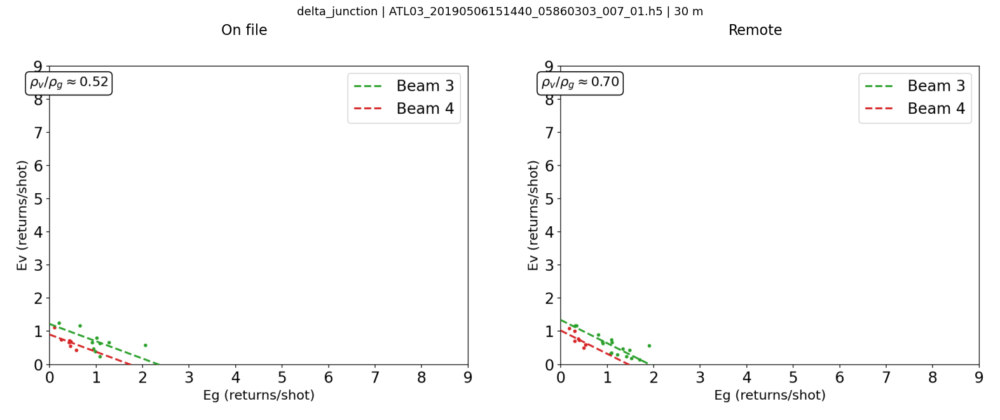


6: delta_junction | ATL03_20190516031713_07310305_007_01.h5
Nothing to rebin for delta_junction file 6's beam 1.
Nothing to rebin for delta_junction file 6's beam 2.
delta_junction: 1 overpasses
  ATL03_20190516031713_07310305_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,68036,269,69,49
1,gt1r,ok,63061,270,64,57
2,gt2l,ok,48372,269,175,103
3,gt2r,ok,51550,269,103,45
4,gt3l,atmosphere_rejected,28501,0,0,0
5,gt3r,atmosphere_rejected,22734,0,0,0


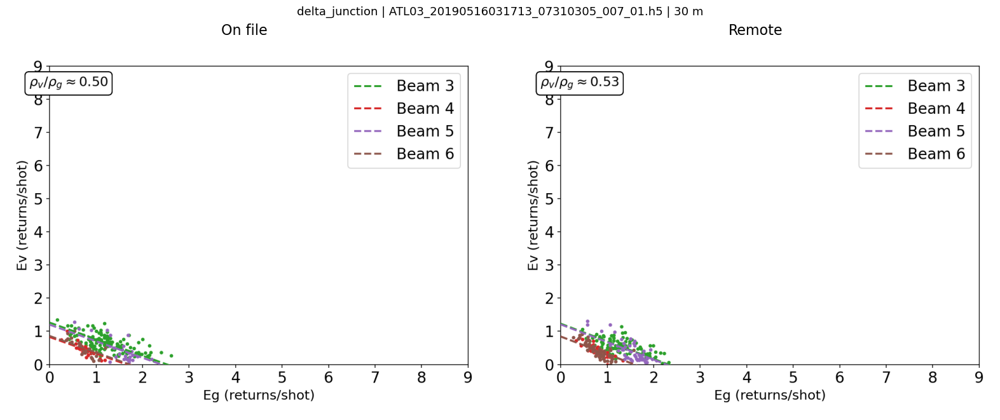


7: delta_junction | ATL03_20190805105422_05860403_007_01.h5
Nothing to rebin for delta_junction file 7's beam 1.
Nothing to rebin for delta_junction file 7's beam 2.
Nothing to rebin for delta_junction file 7's beam 3.
Nothing to rebin for delta_junction file 7's beam 4.
Nothing to rebin for delta_junction file 7's beam 5.
Nothing to rebin for delta_junction file 7's beam 6.
delta_junction: 1 overpasses
  ATL03_20190805105422_05860403_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



8: delta_junction | ATL03_20190814225656_07310405_007_01.h5
Failed to open ATL03 file for delta_junction file 8's beam 1.
Failed to open ATL03 file for delta_junction file 8's beam 2.
Failed to open ATL03 file for delta_junction file 8's beam 3.
Failed to open ATL03 file for delta_junction file 8's beam 4.
Nothing to rebin for delta_junction file 8's beam 5.
Nothing to rebin for delta_junction file 8's beam 6.
delta_junction: 1 overpasses
  ATL03_20190814225656_07310405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



9: delta_junction | ATL03_20190912213302_11730405_007_02.h5
Failed to open ATL03 file for delta_junction file 9's beam 1.
Failed to open ATL03 file for delta_junction file 9's beam 2.
Nothing to rebin for delta_junction file 9's beam 3.
Nothing to rebin for delta_junction file 9's beam 4.
delta_junction: 1 overpasses
  ATL03_20190912213302_11730405_007_02.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,86734.0,269.0,152.0,141.0
5,gt3r,ok,99886.0,270.0,214.0,200.0


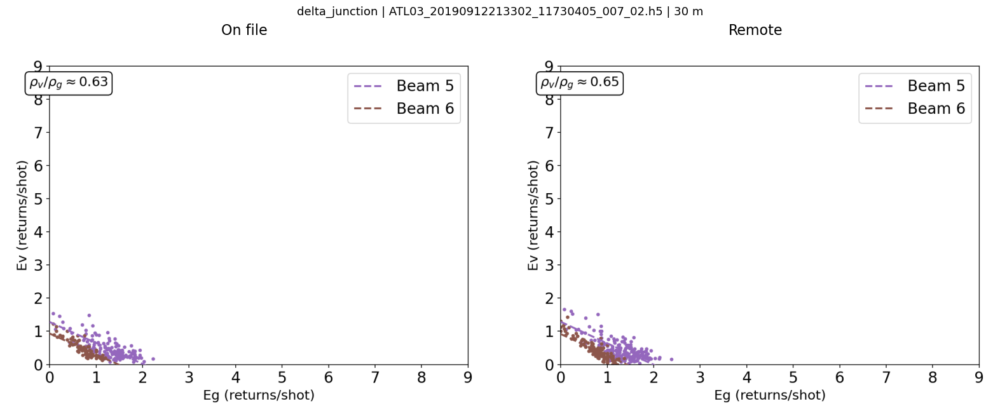


10: delta_junction | ATL03_20191104063416_05860503_007_01.h5
Nothing to rebin for delta_junction file 10's beam 1.
Nothing to rebin for delta_junction file 10's beam 2.
Nothing to rebin for delta_junction file 10's beam 3.
Nothing to rebin for delta_junction file 10's beam 4.
Nothing to rebin for delta_junction file 10's beam 5.
Nothing to rebin for delta_junction file 10's beam 6.
delta_junction: 1 overpasses
  ATL03_20191104063416_05860503_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



11: delta_junction | ATL03_20191113183651_07310505_007_01.h5
Failed to open ATL03 file for delta_junction file 11's beam 1.
Failed to open ATL03 file for delta_junction file 11's beam 2.
Nothing to rebin for delta_junction file 11's beam 3.
Nothing to rebin for delta_junction file 11's beam 4.
Beam 5 in delta_junction file 11 has no data after filtering.
Nothing to rebin for delta_junction file 11's beam 6.
delta_junction: 1 overpasses
  ATL03_20191113183651_07310505_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,ok,46266.0,269.0,3.0,0.0



12: delta_junction | ATL03_20200105033758_01440603_007_01.h5
Failed to open ATL03 file for delta_junction file 12's beam 1.
Failed to open ATL03 file for delta_junction file 12's beam 2.
Nothing to rebin for delta_junction file 12's beam 3.
Nothing to rebin for delta_junction file 12's beam 4.
Beam 5 in delta_junction file 12 has no data after filtering.
Beam 6 in delta_junction file 12 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20200105033758_01440603_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,14293.0,269.0,116.0,0.0
5,gt3r,ok,57674.0,269.0,230.0,0.0


... (2 outputs left out)


14: delta_junction | ATL03_20200312125239_11730605_007_01.h5
Failed to open ATL03 file for delta_junction file 14's beam 1.
Failed to open ATL03 file for delta_junction file 14's beam 2.
Failed to open ATL03 file for delta_junction file 14's beam 3.
Failed to open ATL03 file for delta_junction file 14's beam 4.
Nothing to rebin for delta_junction file 14's beam 5.
Nothing to rebin for delta_junction file 14's beam 6.
delta_junction: 1 overpasses
  ATL03_20200312125239_11730605_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



15: delta_junction | ATL03_20200503215348_05860703_007_01.h5
delta_junction: 1 overpasses
  ATL03_20200503215348_05860703_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,105488,270,233,153
1,gt1r,ok,124820,269,258,150
2,gt2l,ok,95067,270,240,233
3,gt2r,ok,94897,269,254,254
4,gt3l,ok,113161,230,168,145
5,gt3r,ok,166571,212,163,142


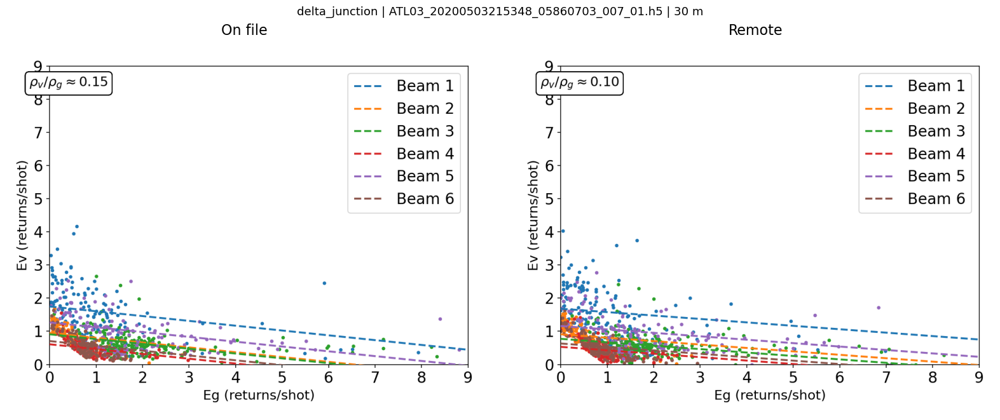


16: delta_junction | ATL03_20200513095624_07310705_007_01.h5
Nothing to rebin for delta_junction file 16's beam 1.
Nothing to rebin for delta_junction file 16's beam 2.
Beam 3 in delta_junction file 16 has no data after filtering.
Beam 4 in delta_junction file 16 has no data after filtering.
Beam 5 in delta_junction file 16 has no data after filtering.
Beam 6 in delta_junction file 16 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20200513095624_07310705_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,4158.0,270.0,7.0,0.0
3,gt2r,ok,13068.0,269.0,56.0,0.0
4,gt3l,ok,4099.0,269.0,16.0,0.0
5,gt3r,ok,17475.0,269.0,42.0,0.0



17: delta_junction | ATL03_20200704185731_01440803_007_01.h5
Failed to open ATL03 file for delta_junction file 17's beam 3.
Failed to open ATL03 file for delta_junction file 17's beam 4.
Failed to open ATL03 file for delta_junction file 17's beam 5.
Failed to open ATL03 file for delta_junction file 17's beam 6.
delta_junction: 1 overpasses
  ATL03_20200704185731_01440803_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,78793.0,54.0,24.0,24.0
5,gt3r,ok,62252.0,81.0,43.0,38.0


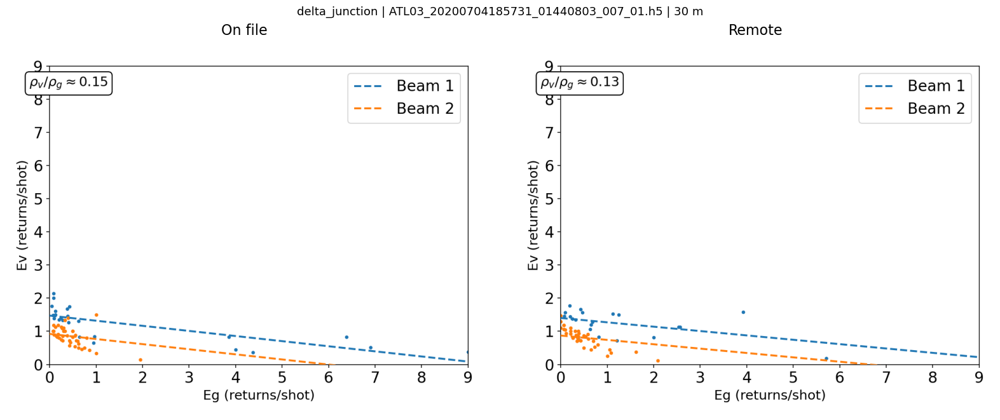


18: delta_junction | ATL03_20200802173335_05860803_007_01.h5
Failed to open ATL03 file for delta_junction file 18's beam 1.
Failed to open ATL03 file for delta_junction file 18's beam 2.
Nothing to rebin for delta_junction file 18's beam 3.
Nothing to rebin for delta_junction file 18's beam 4.
Nothing to rebin for delta_junction file 18's beam 5.
Nothing to rebin for delta_junction file 18's beam 6.
delta_junction: 1 overpasses
  ATL03_20200802173335_05860803_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,atmosphere_rejected,256940.0,269.0,0.0,0.0
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



19: delta_junction | ATL03_20200812053609_07310805_007_01.h5
Nothing to rebin for delta_junction file 19's beam 1.
Nothing to rebin for delta_junction file 19's beam 2.
Beam 3 in delta_junction file 19 has no data after filtering.


/scratch/s1803229/.conda/envs/snow_env/lib/python3.11/site-packages/scipy/interpolate/_interpolate.py:701: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


Beam 4 in delta_junction file 19 has no data after filtering.
Beam 6 in delta_junction file 19 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20200812053609_07310805_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,29195.0,270.0,42.0,13.0
1,gt1r,ok,15791.0,269.0,4.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


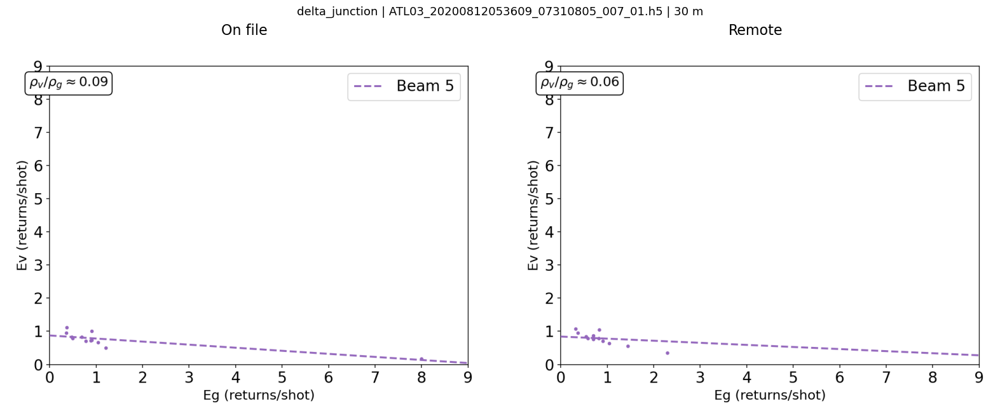


20: delta_junction | ATL03_20201101131324_05860903_007_01.h5
Nothing to rebin for delta_junction file 20's beam 1.
Nothing to rebin for delta_junction file 20's beam 2.
Beam 3 in delta_junction file 20 has no data after filtering.


/scratch/s1803229/.conda/envs/snow_env/lib/python3.11/site-packages/scipy/interpolate/_interpolate.py:701: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


Beam 4 in delta_junction file 20 has no data after filtering.
Nothing to rebin for delta_junction file 20's beam 5.
Nothing to rebin for delta_junction file 20's beam 6.
delta_junction: 1 overpasses
  ATL03_20201101131324_05860903_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,14314.0,269.0,3.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



21: delta_junction | ATL03_20201111011558_07310905_007_01.h5
Beam 1 in delta_junction file 21 has no data after filtering.
Beam 2 in delta_junction file 21 has no data after filtering.
Beam 3 in delta_junction file 21 has no data after filtering.
Beam 4 in delta_junction file 21 has no data after filtering.
Beam 5 in delta_junction file 21 has no data after filtering.
Beam 6 in delta_junction file 21 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20201111011558_07310905_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,60029,235,103,0
1,gt1r,ok,15067,263,101,0
2,gt2l,ok,42693,269,137,0
3,gt2r,ok,13279,269,115,0
4,gt3l,ok,54220,270,178,0
5,gt3r,ok,14017,269,68,0


... (2 outputs left out)


23: delta_junction | ATL03_20210131085318_05861003_007_01.h5
Nothing to rebin for delta_junction file 23's beam 1.
Nothing to rebin for delta_junction file 23's beam 2.
Failed to open ATL03 file for delta_junction file 23's beam 3.
Failed to open ATL03 file for delta_junction file 23's beam 4.
Failed to open ATL03 file for delta_junction file 23's beam 5.
Failed to open ATL03 file for delta_junction file 23's beam 6.
delta_junction: 1 overpasses
  ATL03_20210131085318_05861003_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



24: delta_junction | ATL03_20210209205553_07311005_007_01.h5
Nothing to rebin for delta_junction file 24's beam 3.
Nothing to rebin for delta_junction file 24's beam 4.
Failed to open ATL03 file for delta_junction file 24's beam 5.
Failed to open ATL03 file for delta_junction file 24's beam 6.
delta_junction: 1 overpasses
  ATL03_20210209205553_07311005_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,106664.0,269.0,238.0,161.0
1,gt1r,ok,193148.0,270.0,238.0,179.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


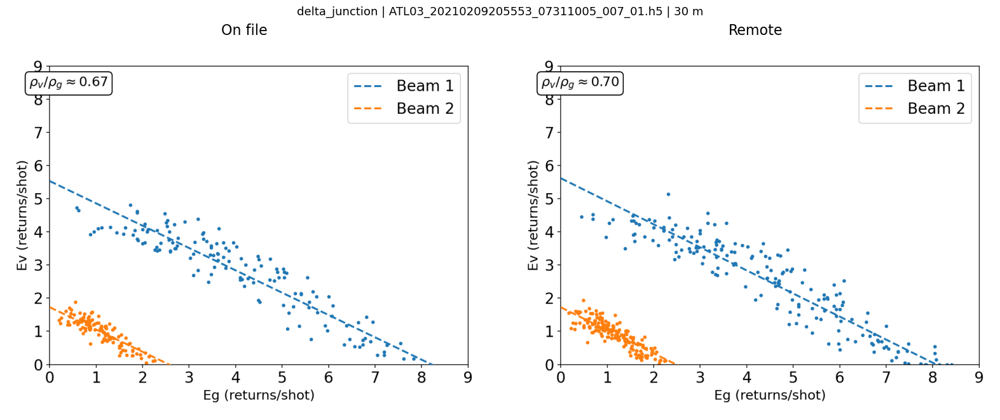


25: delta_junction | ATL03_20210310193155_11731005_007_01.h5
Failed to open ATL03 file for delta_junction file 25's beam 1.
Failed to open ATL03 file for delta_junction file 25's beam 2.
Failed to open ATL03 file for delta_junction file 25's beam 3.
Failed to open ATL03 file for delta_junction file 25's beam 4.
Nothing to rebin for delta_junction file 25's beam 5.
Nothing to rebin for delta_junction file 25's beam 6.
delta_junction: 1 overpasses
  ATL03_20210310193155_11731005_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



26: delta_junction | ATL03_20210412175940_02891105_007_01.h5
Nothing to rebin for delta_junction file 26's beam 1.
Nothing to rebin for delta_junction file 26's beam 2.
Failed to open ATL03 file for delta_junction file 26's beam 3.
Failed to open ATL03 file for delta_junction file 26's beam 4.
Failed to open ATL03 file for delta_junction file 26's beam 5.
Failed to open ATL03 file for delta_junction file 26's beam 6.
delta_junction: 1 overpasses
  ATL03_20210412175940_02891105_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



27: delta_junction | ATL03_20210502043308_05861103_007_01.h5
Beam 2, box 0 in delta_junction file 27 has insufficient data.
delta_junction: 1 overpasses
  ATL03_20210502043308_05861103_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,23145,29,19,5
1,gt1r,ok,37703,56,56,40
2,gt2l,ok,37933,270,143,101
3,gt2r,ok,48844,269,183,129
4,gt3l,ok,43894,270,41,35
5,gt3r,ok,84080,269,55,34


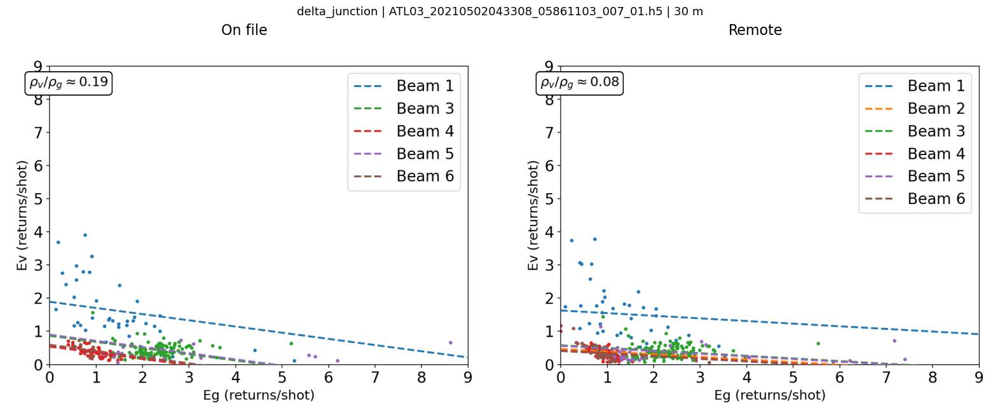


28: delta_junction | ATL03_20210511163544_07311105_007_01.h5
Failed to open ATL03 file for delta_junction file 28's beam 1.
Failed to open ATL03 file for delta_junction file 28's beam 2.
Nothing to rebin for delta_junction file 28's beam 3.
Nothing to rebin for delta_junction file 28's beam 4.
Nothing to rebin for delta_junction file 28's beam 5.
Nothing to rebin for delta_junction file 28's beam 6.
delta_junction: 1 overpasses
  ATL03_20210511163544_07311105_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



29: delta_junction | ATL03_20210703013654_01441203_007_01.h5
Failed to open ATL03 file for delta_junction file 29's beam 1.
Failed to open ATL03 file for delta_junction file 29's beam 2.
Failed to open ATL03 file for delta_junction file 29's beam 3.
Failed to open ATL03 file for delta_junction file 29's beam 4.
Nothing to rebin for delta_junction file 29's beam 5.
Nothing to rebin for delta_junction file 29's beam 6.
delta_junction: 1 overpasses
  ATL03_20210703013654_01441203_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



30: delta_junction | ATL03_20210801001300_05861203_007_01.h5
Failed to open ATL03 file for delta_junction file 30's beam 5.
Failed to open ATL03 file for delta_junction file 30's beam 6.
delta_junction: 1 overpasses
  ATL03_20210801001300_05861203_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,71460.0,269.0,254.0,254.0
1,gt1r,ok,81053.0,270.0,269.0,269.0
2,gt2l,ok,86406.0,251.0,210.0,186.0
3,gt2r,ok,87322.0,223.0,183.0,163.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


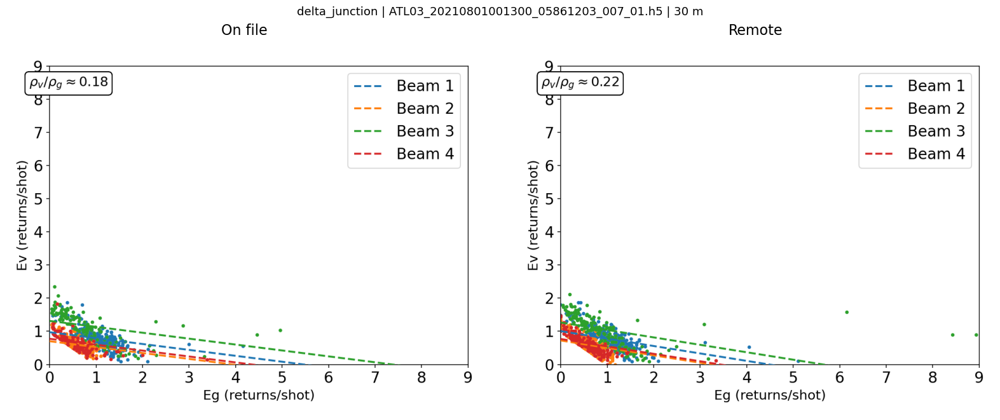


31: delta_junction | ATL03_20210810121536_07311205_007_01.h5
Nothing to rebin for delta_junction file 31's beam 1.
Nothing to rebin for delta_junction file 31's beam 2.
Nothing to rebin for delta_junction file 31's beam 3.
Nothing to rebin for delta_junction file 31's beam 4.
Nothing to rebin for delta_junction file 31's beam 5.
Nothing to rebin for delta_junction file 31's beam 6.
delta_junction: 1 overpasses
  ATL03_20210810121536_07311205_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



32: delta_junction | ATL03_20211001211653_01441303_007_01.h5
Failed to open ATL03 file for delta_junction file 32's beam 1.
Failed to open ATL03 file for delta_junction file 32's beam 2.
Nothing to rebin for delta_junction file 32's beam 3.
Nothing to rebin for delta_junction file 32's beam 4.
Nothing to rebin for delta_junction file 32's beam 5.
Nothing to rebin for delta_junction file 32's beam 6.
delta_junction: 1 overpasses
  ATL03_20211001211653_01441303_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



33: delta_junction | ATL03_20211030195259_05861303_007_01.h5
Failed to open ATL03 file for delta_junction file 33's beam 1.
Failed to open ATL03 file for delta_junction file 33's beam 2.
Failed to open ATL03 file for delta_junction file 33's beam 3.
Failed to open ATL03 file for delta_junction file 33's beam 4.
Nothing to rebin for delta_junction file 33's beam 5.
Nothing to rebin for delta_junction file 33's beam 6.
delta_junction: 1 overpasses
  ATL03_20211030195259_05861303_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (6 outputs left out)


37: delta_junction | ATL03_20220208033523_07311405_007_01.h5
Nothing to rebin for delta_junction file 37's beam 1.
Nothing to rebin for delta_junction file 37's beam 2.
Nothing to rebin for delta_junction file 37's beam 3.
Nothing to rebin for delta_junction file 37's beam 4.
Nothing to rebin for delta_junction file 37's beam 5.
Nothing to rebin for delta_junction file 37's beam 6.
delta_junction: 1 overpasses
  ATL03_20220208033523_07311405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



38: delta_junction | ATL03_20220430111239_05861503_007_01.h5
Beam 3 in delta_junction file 38 has no data after filtering.
Beam 4 in delta_junction file 38 has no data after filtering.
Nothing to rebin for delta_junction file 38's beam 5.
Nothing to rebin for delta_junction file 38's beam 6.
delta_junction: 1 overpasses
  ATL03_20220430111239_05861503_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,40945.0,269.0,245.0,0.0
3,gt2r,ok,12348.0,269.0,236.0,0.0
4,gt3l,ok,58405.0,270.0,109.0,102.0
5,gt3r,ok,14991.0,269.0,39.0,31.0


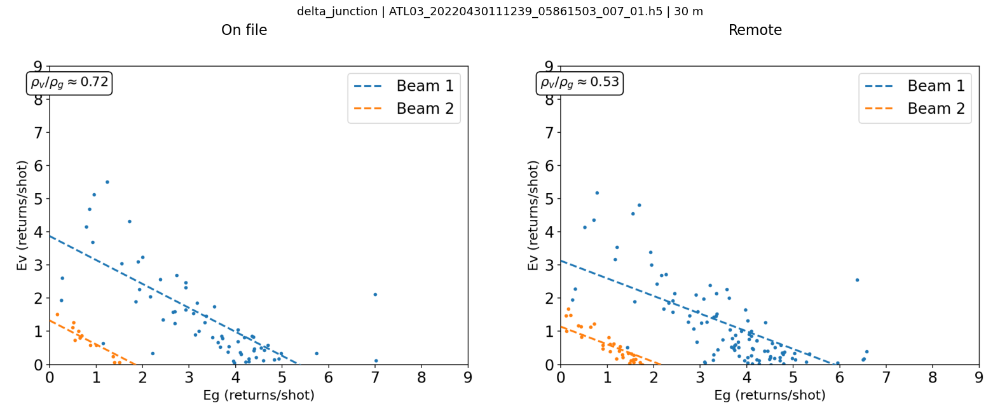


39: delta_junction | ATL03_20220509231511_07311505_007_01.h5
Nothing to rebin for delta_junction file 39's beam 3.
Beam 4 in delta_junction file 39 has no data after filtering.
Failed to open ATL03 file for delta_junction file 39's beam 5.
Failed to open ATL03 file for delta_junction file 39's beam 6.
delta_junction: 1 overpasses
  ATL03_20220509231511_07311505_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,atmosphere_rejected,111451.0,31.0,0.0,0.0
3,gt2r,ok,164862.0,57.0,13.0,0.0
4,gt3l,ok,298503.0,270.0,89.0,51.0
5,gt3r,ok,242317.0,261.0,83.0,51.0


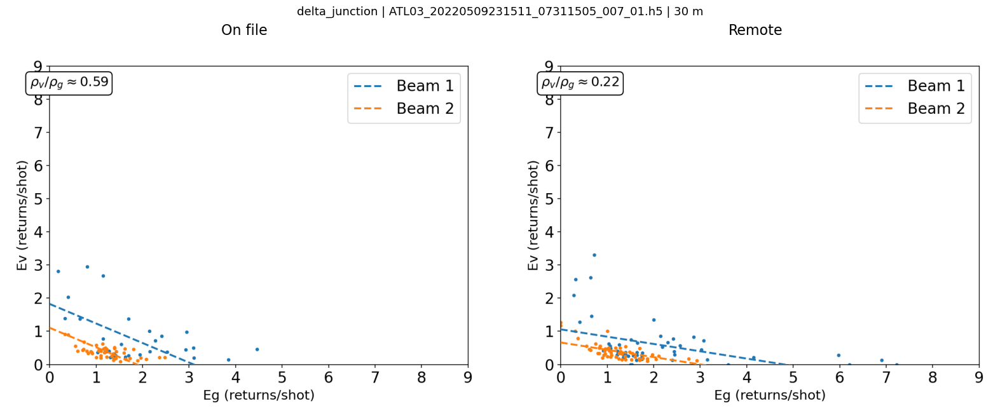


40: delta_junction | ATL03_20220730065242_05861603_007_01.h5
Beam 3 in delta_junction file 40 has no data after filtering.
Beam 4 in delta_junction file 40 has no data after filtering.
Beam 5 in delta_junction file 40 has no data after filtering.
Beam 6 in delta_junction file 40 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20220730065242_05861603_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,6761,270,167,97
1,gt1r,ok,17963,269,240,124
2,gt2l,ok,5773,270,99,0
3,gt2r,ok,11652,269,262,0
4,gt3l,ok,9347,219,79,0
5,gt3r,ok,22327,200,176,0


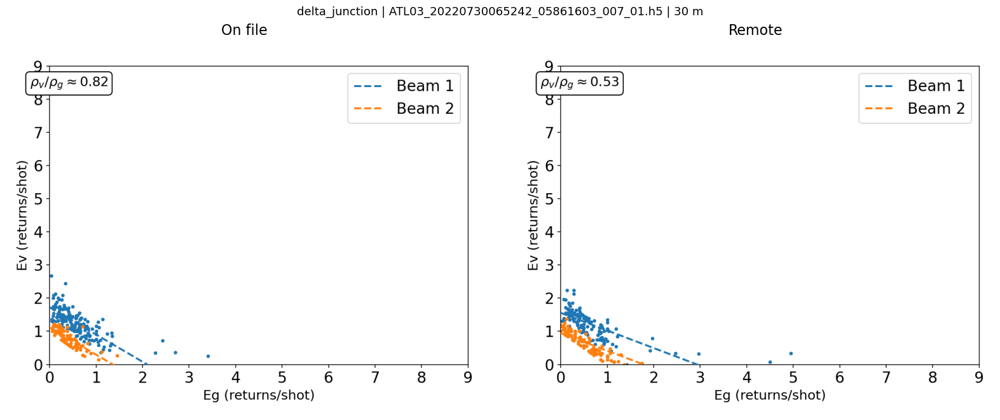


41: delta_junction | ATL03_20220808185517_07311605_007_01.h5
Nothing to rebin for delta_junction file 41's beam 1.
Nothing to rebin for delta_junction file 41's beam 2.
Nothing to rebin for delta_junction file 41's beam 3.
Nothing to rebin for delta_junction file 41's beam 4.
Nothing to rebin for delta_junction file 41's beam 5.
Nothing to rebin for delta_junction file 41's beam 6.
delta_junction: 1 overpasses
  ATL03_20220808185517_07311605_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



42: delta_junction | ATL03_20220930035627_01441703_007_01.h5
Failed to open ATL03 file for delta_junction file 42's beam 1.
Failed to open ATL03 file for delta_junction file 42's beam 2.
Failed to open ATL03 file for delta_junction file 42's beam 3.
Failed to open ATL03 file for delta_junction file 42's beam 4.
Nothing to rebin for delta_junction file 42's beam 5.
Nothing to rebin for delta_junction file 42's beam 6.
delta_junction: 1 overpasses
  ATL03_20220930035627_01441703_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



43: delta_junction | ATL03_20221029023225_05861703_007_01.h5
Nothing to rebin for delta_junction file 43's beam 3.
Nothing to rebin for delta_junction file 43's beam 4.
Failed to open ATL03 file for delta_junction file 43's beam 5.
Failed to open ATL03 file for delta_junction file 43's beam 6.
delta_junction: 1 overpasses
  ATL03_20221029023225_05861703_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,25810.0,269.0,143.0,136.0
1,gt1r,ok,102114.0,269.0,213.0,206.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


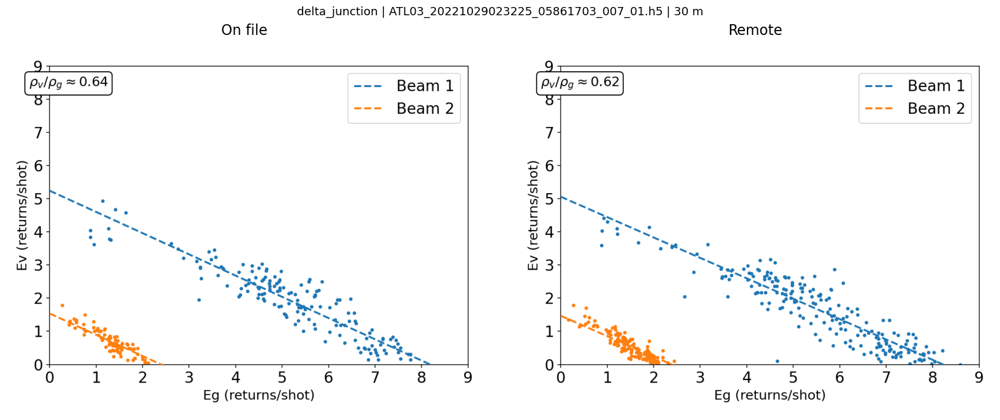


44: delta_junction | ATL03_20221107143459_07311705_007_01.h5
Nothing to rebin for delta_junction file 44's beam 1.
Nothing to rebin for delta_junction file 44's beam 2.
Nothing to rebin for delta_junction file 44's beam 3.
Nothing to rebin for delta_junction file 44's beam 4.
Failed to open ATL03 file for delta_junction file 44's beam 5.
Failed to open ATL03 file for delta_junction file 44's beam 6.
delta_junction: 1 overpasses
  ATL03_20221107143459_07311705_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



45: delta_junction | ATL03_20221206131059_11731705_007_01.h5
Failed to open ATL03 file for delta_junction file 45's beam 1.
Failed to open ATL03 file for delta_junction file 45's beam 2.
Failed to open ATL03 file for delta_junction file 45's beam 3.
Failed to open ATL03 file for delta_junction file 45's beam 4.
Nothing to rebin for delta_junction file 45's beam 5.
Nothing to rebin for delta_junction file 45's beam 6.
delta_junction: 1 overpasses
  ATL03_20221206131059_11731705_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



46: delta_junction | ATL03_20221229233610_01441803_007_01.h5
Failed to open ATL03 file for delta_junction file 46's beam 1.
Failed to open ATL03 file for delta_junction file 46's beam 2.
Failed to open ATL03 file for delta_junction file 46's beam 3.
Failed to open ATL03 file for delta_junction file 46's beam 4.
Nothing to rebin for delta_junction file 46's beam 5.
Nothing to rebin for delta_junction file 46's beam 6.
delta_junction: 1 overpasses
  ATL03_20221229233610_01441803_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



47: delta_junction | ATL03_20230127221215_05861803_007_01.h5
Failed to open ATL03 file for delta_junction file 47's beam 5.
Failed to open ATL03 file for delta_junction file 47's beam 6.
delta_junction: 1 overpasses
  ATL03_20230127221215_05861803_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,91471.0,269.0,182.0,182.0
1,gt1r,ok,160988.0,270.0,244.0,244.0
2,gt2l,ok,112240.0,250.0,164.0,150.0
3,gt2r,ok,149399.0,223.0,147.0,133.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


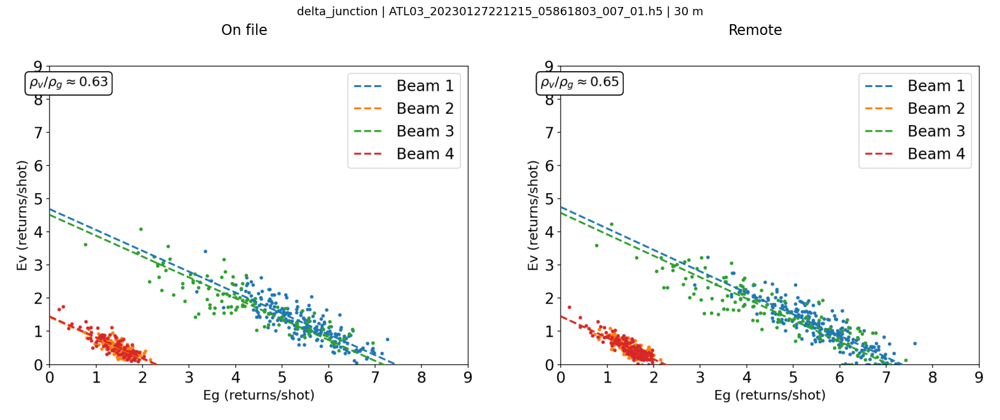


48: delta_junction | ATL03_20230206101448_07311805_007_01.h5
Beam 1 in delta_junction file 48 has no data after filtering.
Beam 2 in delta_junction file 48 has no data after filtering.
Beam 3 in delta_junction file 48 has no data after filtering.
Beam 4 in delta_junction file 48 has no data after filtering.
Nothing to rebin for delta_junction file 48's beam 5.
Nothing to rebin for delta_junction file 48's beam 6.
delta_junction: 1 overpasses
  ATL03_20230206101448_07311805_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,10214,269,21,0
1,gt1r,ok,41768,270,71,0
2,gt2l,ok,8996,269,97,0
3,gt2r,ok,30765,269,180,0
4,gt3l,atmosphere_rejected,6801,2,0,0
5,gt3r,atmosphere_rejected,22082,0,0,0



49: delta_junction | ATL03_20230409071829_02891905_007_01.h5
Nothing to rebin for delta_junction file 49's beam 1.
Nothing to rebin for delta_junction file 49's beam 2.
Nothing to rebin for delta_junction file 49's beam 3.
Nothing to rebin for delta_junction file 49's beam 4.
Nothing to rebin for delta_junction file 49's beam 5.
Nothing to rebin for delta_junction file 49's beam 6.
delta_junction: 1 overpasses
  ATL03_20230409071829_02891905_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



50: delta_junction | ATL03_20230428175154_05861903_007_01.h5
Nothing to rebin for delta_junction file 50's beam 1.
Nothing to rebin for delta_junction file 50's beam 2.
delta_junction: 1 overpasses
  ATL03_20230428175154_05861903_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,269985,270,220,30
1,gt1r,ok,241940,262,170,37
2,gt2l,ok,259701,269,102,18
3,gt2r,ok,290288,270,259,57
4,gt3l,atmosphere_rejected,112502,0,0,0
5,gt3r,atmosphere_rejected,63799,0,0,0


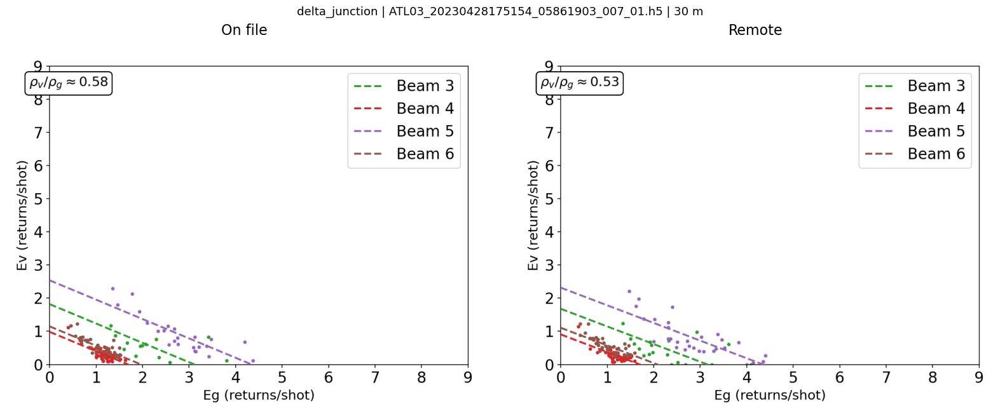


51: delta_junction | ATL03_20230508055430_07311905_007_01.h5
Beam 1 in delta_junction file 51 has no data after filtering.
Beam 2 in delta_junction file 51 has no data after filtering.
Beam 3 in delta_junction file 51 has no data after filtering.
Beam 4 in delta_junction file 51 has no data after filtering.
Nothing to rebin for delta_junction file 51's beam 5.
Beam 6 in delta_junction file 51 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20230508055430_07311905_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,atmosphere_rejected,9410.0,21.0,0.0,0.0
2,gt2l,ok,28761.0,269.0,34.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,35955.0,270.0,171.0,0.0
5,gt3r,ok,17977.0,269.0,22.0,0.0



52: delta_junction | ATL03_20230629145514_01442003_007_01.h5
Nothing to rebin for delta_junction file 52's beam 1.
Nothing to rebin for delta_junction file 52's beam 2.
Failed to open ATL03 file for delta_junction file 52's beam 3.
Failed to open ATL03 file for delta_junction file 52's beam 4.
Failed to open ATL03 file for delta_junction file 52's beam 5.
Failed to open ATL03 file for delta_junction file 52's beam 6.
delta_junction: 1 overpasses
  ATL03_20230629145514_01442003_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



53: delta_junction | ATL03_20230728133107_05862003_007_01.h5
Failed to open ATL03 file for delta_junction file 53's beam 1.
Failed to open ATL03 file for delta_junction file 53's beam 2.
Nothing to rebin for delta_junction file 53's beam 3.
Nothing to rebin for delta_junction file 53's beam 4.
delta_junction: 1 overpasses
  ATL03_20230728133107_05862003_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,27484.0,269.0,78.0,57.0
1,gt1r,ok,20394.0,269.0,4.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


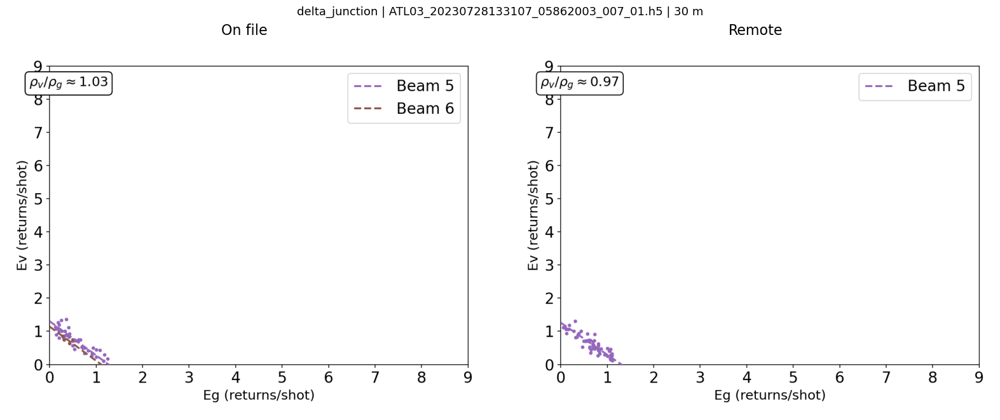


54: delta_junction | ATL03_20230807013340_07312005_007_01.h5
Nothing to rebin for delta_junction file 54's beam 1.
Nothing to rebin for delta_junction file 54's beam 2.
delta_junction: 1 overpasses
  ATL03_20230807013340_07312005_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,135206.0,270.0,145.0,123.0
1,gt1r,ok,98535.0,257.0,100.0,84.0
2,gt2l,ok,138495.0,269.0,48.0,27.0
3,gt2r,ok,119330.0,224.0,28.0,22.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


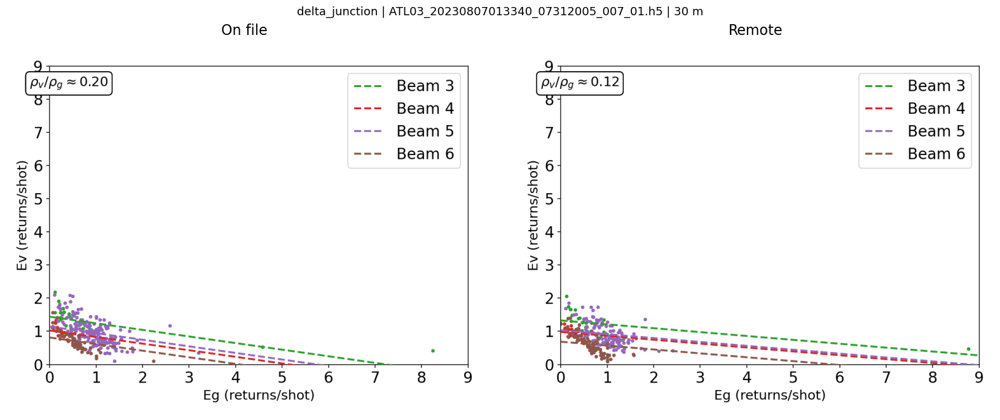


55: delta_junction | ATL03_20230928103437_01442103_007_01.h5
Nothing to rebin for delta_junction file 55's beam 1.
Nothing to rebin for delta_junction file 55's beam 2.
Failed to open ATL03 file for delta_junction file 55's beam 3.
Failed to open ATL03 file for delta_junction file 55's beam 4.
Failed to open ATL03 file for delta_junction file 55's beam 5.
Failed to open ATL03 file for delta_junction file 55's beam 6.
delta_junction: 1 overpasses
  ATL03_20230928103437_01442103_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



56: delta_junction | ATL03_20231027091055_05862103_007_01.h5
Failed to open ATL03 file for delta_junction file 56's beam 1.
Failed to open ATL03 file for delta_junction file 56's beam 2.


/scratch/s1803229/.conda/envs/snow_env/lib/python3.11/site-packages/scipy/interpolate/_interpolate.py:701: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


Beam 3 in delta_junction file 56 has no data after filtering.
Nothing to rebin for delta_junction file 56's beam 4.
delta_junction: 1 overpasses
  ATL03_20231027091055_05862103_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,86514.0,269.0,193.0,173.0
1,gt1r,ok,20971.0,270.0,65.0,51.0
2,gt2l,ok,23169.0,5.0,5.0,5.0
3,gt2r,atmosphere_rejected,5374.0,0.0,0.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


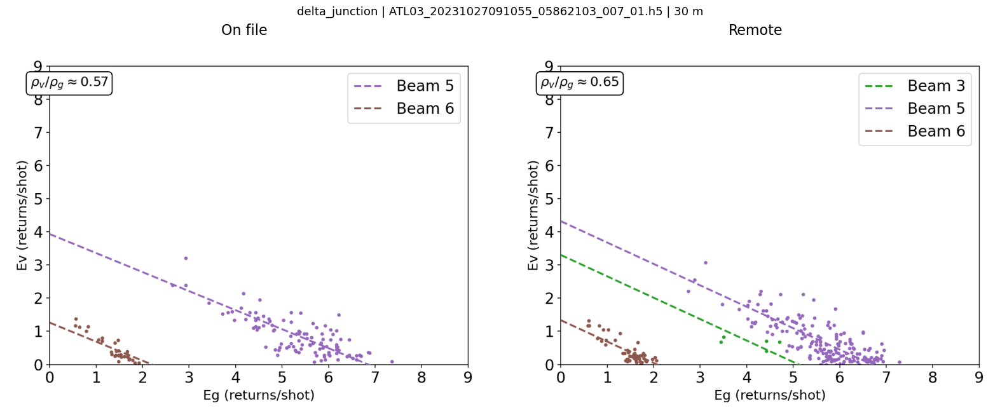


57: delta_junction | ATL03_20231105211320_07312105_007_01.h5
Nothing to rebin for delta_junction file 57's beam 1.
Nothing to rebin for delta_junction file 57's beam 2.
Nothing to rebin for delta_junction file 57's beam 3.
Nothing to rebin for delta_junction file 57's beam 4.
Nothing to rebin for delta_junction file 57's beam 5.
Nothing to rebin for delta_junction file 57's beam 6.
delta_junction: 1 overpasses
  ATL03_20231105211320_07312105_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



58: delta_junction | ATL03_20231228061421_01442203_007_01.h5
Failed to open ATL03 file for delta_junction file 58's beam 1.
Failed to open ATL03 file for delta_junction file 58's beam 2.
Failed to open ATL03 file for delta_junction file 58's beam 3.
Failed to open ATL03 file for delta_junction file 58's beam 4.
Nothing to rebin for delta_junction file 58's beam 5.
Nothing to rebin for delta_junction file 58's beam 6.
delta_junction: 1 overpasses
  ATL03_20231228061421_01442203_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



59: delta_junction | ATL03_20240126045009_05862203_007_01.h5
Failed to open ATL03 file for delta_junction file 59's beam 5.
Failed to open ATL03 file for delta_junction file 59's beam 6.
delta_junction: 1 overpasses
  ATL03_20240126045009_05862203_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,23554.0,269.0,210.0,210.0
1,gt1r,ok,96203.0,270.0,234.0,234.0
2,gt2l,ok,23114.0,250.0,129.0,122.0
3,gt2r,ok,75658.0,222.0,178.0,158.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


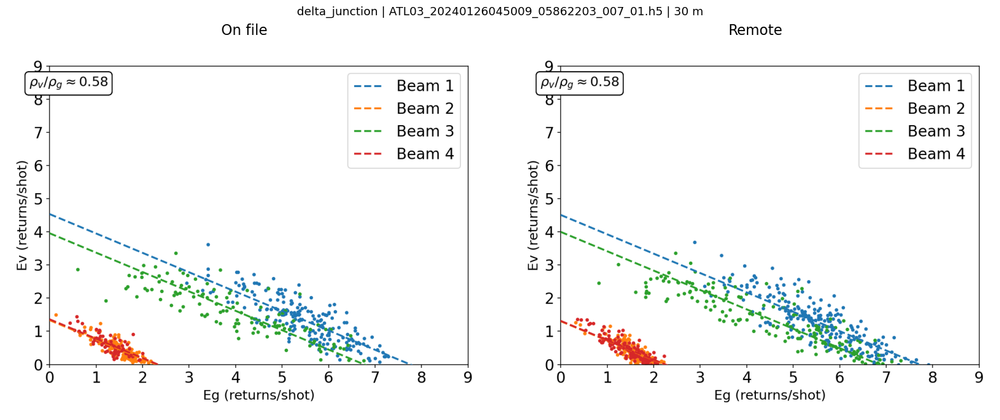


60: delta_junction | ATL03_20240204165250_07312205_007_01.h5
Nothing to rebin for delta_junction file 60's beam 1.
Nothing to rebin for delta_junction file 60's beam 2.
Nothing to rebin for delta_junction file 60's beam 3.
Nothing to rebin for delta_junction file 60's beam 4.
Nothing to rebin for delta_junction file 60's beam 5.
Nothing to rebin for delta_junction file 60's beam 6.
delta_junction: 1 overpasses
  ATL03_20240204165250_07312205_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



61: delta_junction | ATL03_20240426002935_05862303_007_01.h5
Failed to open ATL03 file for delta_junction file 61's beam 5.
Nothing to rebin for delta_junction file 61's beam 6.
delta_junction: 1 overpasses
  ATL03_20240426002935_05862303_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,71068.0,269.0,218.0,195.0
1,gt1r,ok,81768.0,270.0,233.0,211.0
2,gt2l,ok,103168.0,269.0,218.0,189.0
3,gt2r,ok,104042.0,270.0,194.0,182.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


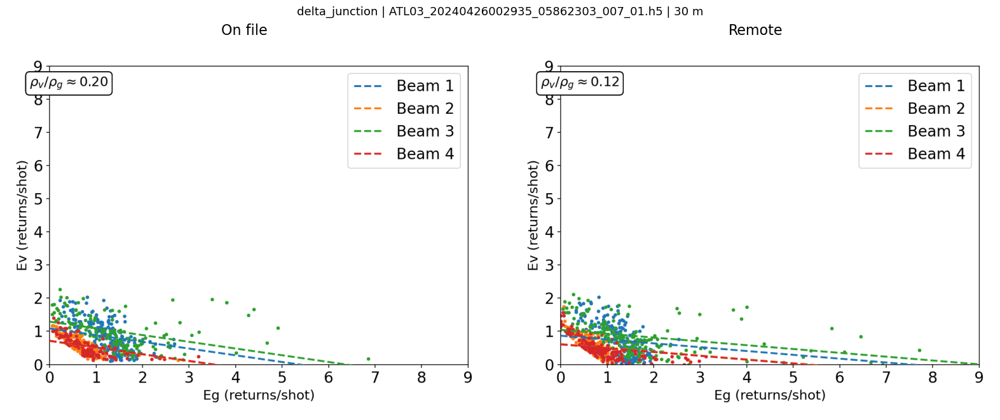


62: delta_junction | ATL03_20240626213338_01442403_007_01.h5
Nothing to rebin for delta_junction file 62's beam 1.
Nothing to rebin for delta_junction file 62's beam 2.
Failed to open ATL03 file for delta_junction file 62's beam 3.
Failed to open ATL03 file for delta_junction file 62's beam 4.
Failed to open ATL03 file for delta_junction file 62's beam 5.
Failed to open ATL03 file for delta_junction file 62's beam 6.
delta_junction: 1 overpasses
  ATL03_20240626213338_01442403_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



63: delta_junction | ATL03_20240725200919_05862403_007_01.h5
Nothing to rebin for delta_junction file 63's beam 1.
Nothing to rebin for delta_junction file 63's beam 2.
Beam 4 in delta_junction file 63 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20240725200919_05862403_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,151442.0,269.0,200.0,152.0
1,gt1r,ok,154790.0,269.0,27.0,16.0
2,gt2l,ok,111858.0,269.0,180.0,167.0
3,gt2r,ok,155906.0,267.0,2.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


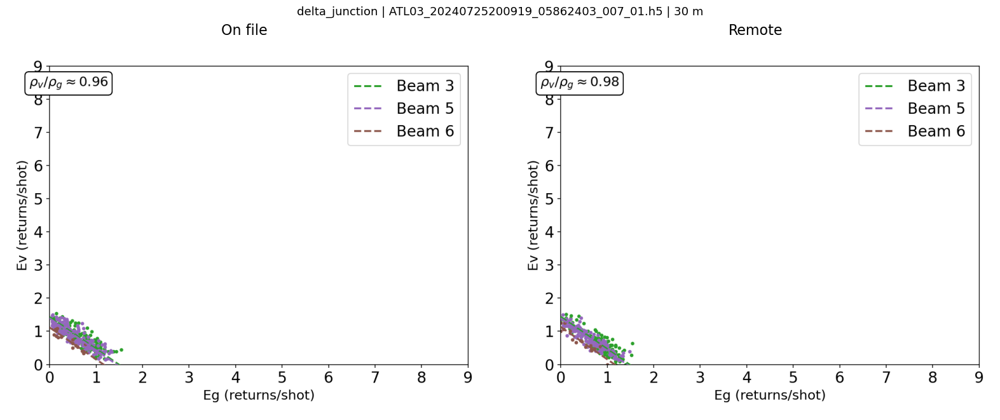


64: delta_junction | ATL03_20240804081206_07312405_007_01.h5
Beam 1 in delta_junction file 64 has no data after filtering.
Beam 2 in delta_junction file 64 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20240804081206_07312405_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,17601,242,226,215
1,gt1r,ok,4471,269,172,161
2,gt2l,ok,12939,269,262,249
3,gt2r,ok,3864,269,195,178
4,gt3l,ok,22473,269,205,0
5,gt3r,ok,6121,269,120,0


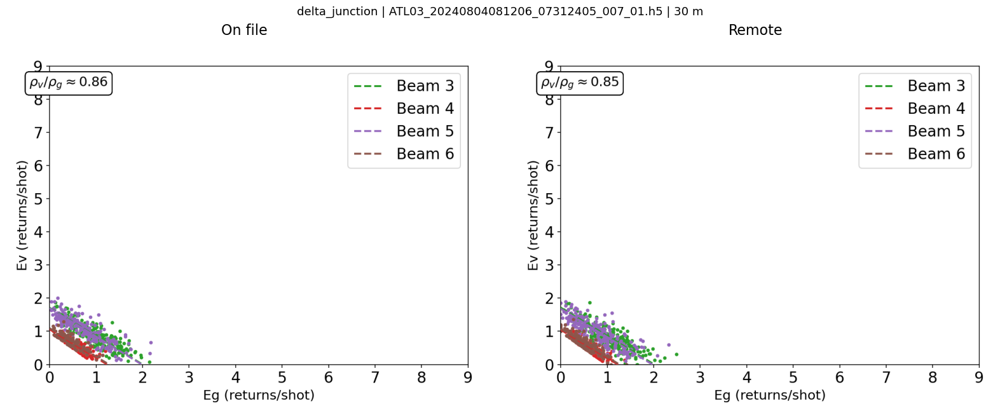


65: delta_junction | ATL03_20240925171302_01442503_007_01.h5
Nothing to rebin for delta_junction file 65's beam 1.
Nothing to rebin for delta_junction file 65's beam 2.
Nothing to rebin for delta_junction file 65's beam 3.
Nothing to rebin for delta_junction file 65's beam 4.
Failed to open ATL03 file for delta_junction file 65's beam 5.
Failed to open ATL03 file for delta_junction file 65's beam 6.
delta_junction: 1 overpasses
  ATL03_20240925171302_01442503_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



66: delta_junction | ATL03_20241024154900_05862503_007_01.h5
Failed to open ATL03 file for delta_junction file 66's beam 1.
Failed to open ATL03 file for delta_junction file 66's beam 2.
delta_junction: 1 overpasses
  ATL03_20241024154900_05862503_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,83982.0,269.0,244.0,244.0
1,gt1r,ok,20242.0,270.0,224.0,224.0
2,gt2l,ok,63914.0,247.0,185.0,170.0
3,gt2r,ok,18526.0,220.0,111.0,111.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


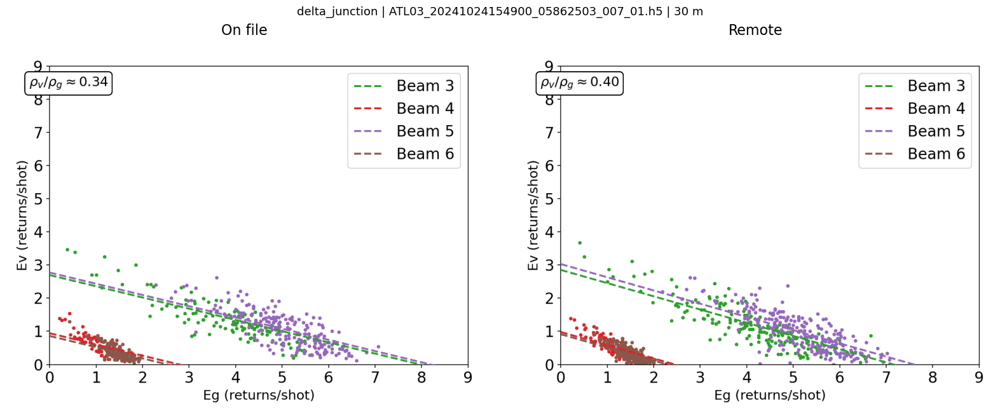


67: delta_junction | ATL03_20241103035139_07312505_007_01.h5
Failed to open ATL03 file for delta_junction file 67's beam 1.
Failed to open ATL03 file for delta_junction file 67's beam 2.
Nothing to rebin for delta_junction file 67's beam 3.
Nothing to rebin for delta_junction file 67's beam 4.
Beam 5 in delta_junction file 67 has no data after filtering.
Beam 6 in delta_junction file 67 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20241103035139_07312505_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,20319.0,269.0,179.0,0.0
1,gt1r,ok,4609.0,268.0,61.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



68: delta_junction | ATL03_20241202022730_11732505_007_01.h5
Beam 1 in delta_junction file 68 has no data after filtering.
Beam 2 in delta_junction file 68 has no data after filtering.
Failed to open ATL03 file for delta_junction file 68's beam 3.
Failed to open ATL03 file for delta_junction file 68's beam 4.
Failed to open ATL03 file for delta_junction file 68's beam 5.
Failed to open ATL03 file for delta_junction file 68's beam 6.
delta_junction: 1 overpasses
  ATL03_20241202022730_11732505_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,28394.0,24.0,13.0,0.0
5,gt3r,ok,8887.0,53.0,14.0,0.0



69: delta_junction | ATL03_20250123112837_05862603_007_01.h5
Failed to open ATL03 file for delta_junction file 69's beam 1.
Failed to open ATL03 file for delta_junction file 69's beam 2.
Beam 3 in delta_junction file 69 has no data after filtering.
Beam 4 in delta_junction file 69 has no data after filtering.
Beam 5 in delta_junction file 69 has no data after filtering.
Beam 6 in delta_junction file 69 has no data after filtering.
delta_junction: 1 overpasses
  ATL03_20250123112837_05862603_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,15195.0,269.0,113.0,0.0
1,gt1r,ok,3519.0,270.0,10.0,0.0
2,gt2l,ok,15435.0,251.0,97.0,0.0
3,gt2r,ok,4396.0,222.0,9.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


... (8 outputs left out)


74: lacclair | ATL03_20190506102318_05830302_007_01.h5
Nothing to rebin for lacclair file 74's beam 1.
Nothing to rebin for lacclair file 74's beam 2.
Failed to open ATL03 file for lacclair file 74's beam 3.
Failed to open ATL03 file for lacclair file 74's beam 4.
Failed to open ATL03 file for lacclair file 74's beam 5.
Failed to open ATL03 file for lacclair file 74's beam 6.
lacclair: 1 overpasses
  ATL03_20190506102318_05830302_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,atmosphere_rejected,1770.0,0.0,0.0,0.0



75: lacclair | ATL03_20190713192557_02400406_007_01.h5
Nothing to rebin for lacclair file 75's beam 5.
Nothing to rebin for lacclair file 75's beam 6.
lacclair: 1 overpasses
  ATL03_20190713192557_02400406_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,35631.0,268.0,53.0,25.0
3,gt2r,ok,34417.0,268.0,49.0,22.0
4,gt3l,ok,44166.0,268.0,143.0,132.0
5,gt3r,ok,36169.0,269.0,53.0,47.0


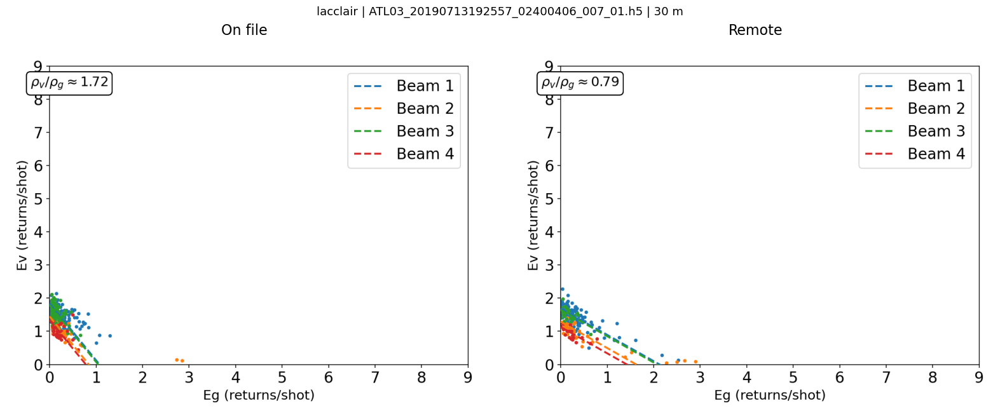


76: lacclair | ATL03_20190811180209_06820406_007_01.h5
Beam 2 in lacclair file 76 has no data after filtering.
Nothing to rebin for lacclair file 76's beam 3.
Nothing to rebin for lacclair file 76's beam 4.
Failed to open ATL03 file for lacclair file 76's beam 5.
Failed to open ATL03 file for lacclair file 76's beam 6.
lacclair: 1 overpasses
  ATL03_20190811180209_06820406_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,74002.0,268.0,49.0,6.0
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


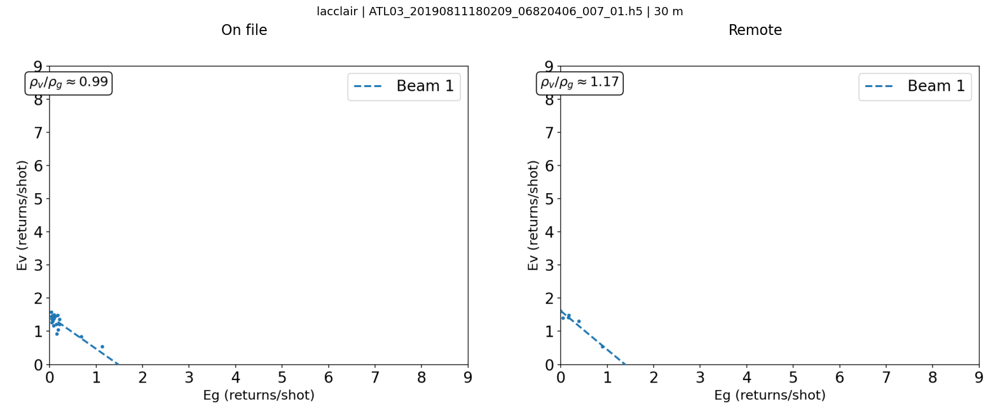


77: lacclair | ATL03_20190903043904_10250402_007_01.h5
Nothing to rebin for lacclair file 77's beam 1.
Nothing to rebin for lacclair file 77's beam 2.
Beam 3 in lacclair file 77 has no data after filtering.
Beam 4 in lacclair file 77 has no data after filtering.
Beam 5 in lacclair file 77 has no data after filtering.
Nothing to rebin for lacclair file 77's beam 6.
lacclair: 1 overpasses
  ATL03_20190903043904_10250402_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,3348.0,213.0,3.0,0.0
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



78: lacclair | ATL03_20191203001854_10250502_007_01.h5
Nothing to rebin for lacclair file 78's beam 5.
Nothing to rebin for lacclair file 78's beam 6.
lacclair: 1 overpasses
  ATL03_20191203001854_10250502_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,17699.0,268.0,221.0,157.0
1,gt1r,ok,71649.0,268.0,259.0,200.0
2,gt2l,ok,16394.0,267.0,141.0,102.0
3,gt2r,ok,57045.0,269.0,180.0,123.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


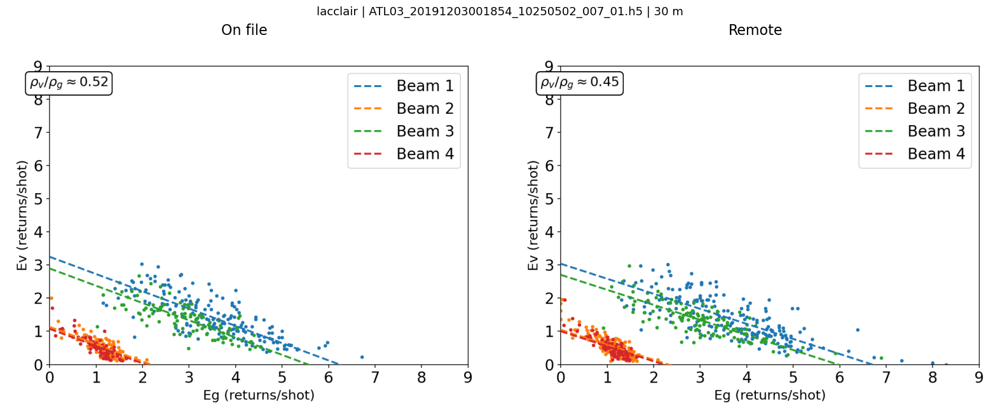


79: lacclair | ATL03_20200111104545_02400606_007_01.h5
Failed to open ATL03 file for lacclair file 79's beam 1.
Failed to open ATL03 file for lacclair file 79's beam 2.
Failed to open ATL03 file for lacclair file 79's beam 3.
Failed to open ATL03 file for lacclair file 79's beam 4.
Failed to open ATL03 file for lacclair file 79's beam 5.
Failed to open ATL03 file for lacclair file 79's beam 6.
lacclair: 1 overpasses
  ATL03_20200111104545_02400606_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



80: lacclair | ATL03_20200202212238_05830602_007_01.h5
Failed to open ATL03 file for lacclair file 80's beam 1.
Failed to open ATL03 file for lacclair file 80's beam 2.
Beam 3 in lacclair file 80 has no data after filtering.
Beam 4 in lacclair file 80 has no data after filtering.
Beam 5 in lacclair file 80 has no data after filtering.
Beam 6 in lacclair file 80 has no data after filtering.
lacclair: 1 overpasses
  ATL03_20200202212238_05830602_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,12429.0,268.0,92.0,0.0
3,gt2r,ok,20998.0,268.0,178.0,0.0
4,gt3l,ok,13419.0,268.0,60.0,0.0
5,gt3r,ok,34687.0,268.0,189.0,0.0



81: lacclair | ATL03_20200411062533_02400706_007_01.h5
Beam 1 in lacclair file 81 has no data after filtering.
Nothing to rebin for lacclair file 81's beam 2.
Nothing to rebin for lacclair file 81's beam 3.
Nothing to rebin for lacclair file 81's beam 4.
Failed to open ATL03 file for lacclair file 81's beam 5.
Failed to open ATL03 file for lacclair file 81's beam 6.
lacclair: 1 overpasses
  ATL03_20200411062533_02400706_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,ok,2055.0,260.0,3.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


... (2 outputs left out)


83: lacclair | ATL03_20200711020519_02400806_007_01.h5
Failed to open ATL03 file for lacclair file 83's beam 1.
Failed to open ATL03 file for lacclair file 83's beam 2.
Failed to open ATL03 file for lacclair file 83's beam 3.
Failed to open ATL03 file for lacclair file 83's beam 4.
Nothing to rebin for lacclair file 83's beam 5.
Nothing to rebin for lacclair file 83's beam 6.
lacclair: 1 overpasses
  ATL03_20200711020519_02400806_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



84: lacclair | ATL03_20200802124213_05830802_007_01.h5
Nothing to rebin for lacclair file 84's beam 3.
Nothing to rebin for lacclair file 84's beam 4.
Failed to open ATL03 file for lacclair file 84's beam 5.
Failed to open ATL03 file for lacclair file 84's beam 6.
lacclair: 1 overpasses
  ATL03_20200802124213_05830802_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,25590.0,160.0,27.0,18.0
5,gt3r,ok,17389.0,119.0,16.0,9.0


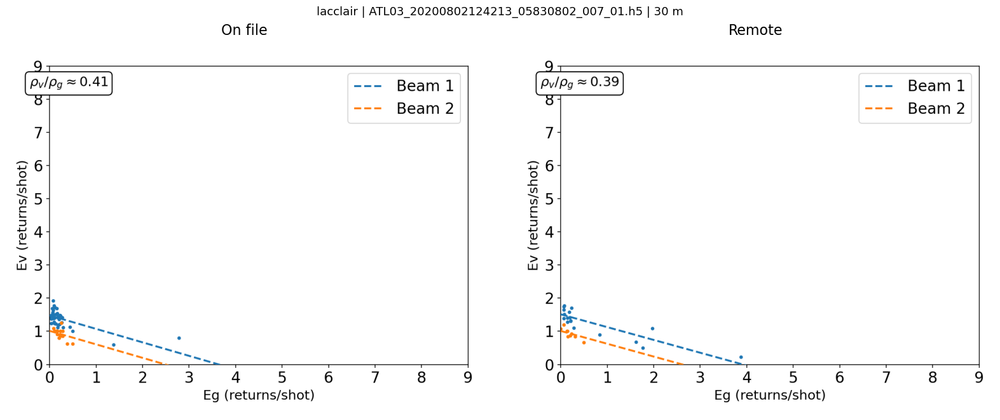


85: lacclair | ATL03_20201009214506_02400906_007_01.h5
Nothing to rebin for lacclair file 85's beam 1.
Failed to open ATL03 file for lacclair file 85's beam 2.
Nothing to rebin for lacclair file 85's beam 3.
Nothing to rebin for lacclair file 85's beam 4.
Nothing to rebin for lacclair file 85's beam 5.
Nothing to rebin for lacclair file 85's beam 6.
lacclair: 1 overpasses
  ATL03_20201009214506_02400906_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



86: lacclair | ATL03_20210131040156_05831002_007_01.h5
lacclair: 1 overpasses
  ATL03_20210131040156_05831002_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,19185,201,142,55
1,gt1r,ok,78098,237,214,76
2,gt2l,ok,16736,269,217,140
3,gt2r,ok,54596,268,251,164
4,gt3l,ok,19016,269,161,54
5,gt3r,ok,74955,268,215,66


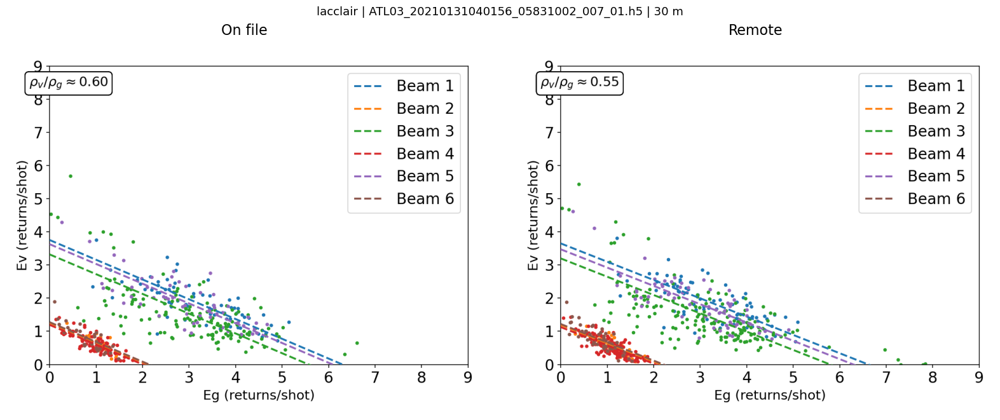


87: lacclair | ATL03_20210206160107_06821006_007_01.h5
Failed to open ATL03 file for lacclair file 87's beam 1.
Failed to open ATL03 file for lacclair file 87's beam 2.
Failed to open ATL03 file for lacclair file 87's beam 3.
Failed to open ATL03 file for lacclair file 87's beam 4.
Beam 5 in lacclair file 87 has no data after filtering.
Beam 6 in lacclair file 87 has no data after filtering.
lacclair: 1 overpasses
  ATL03_20210206160107_06821006_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,52972.0,97.0,65.0,0.0
5,gt3r,ok,109860.0,129.0,90.0,0.0



88: lacclair | ATL03_20210409130453_02401106_007_01.h5
Nothing to rebin for lacclair file 88's beam 1.
Nothing to rebin for lacclair file 88's beam 2.
lacclair: 1 overpasses
  ATL03_20210409130453_02401106_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,52890.0,268.0,124.0,43.0
3,gt2r,ok,57690.0,269.0,151.0,48.0
4,gt3l,ok,37764.0,269.0,227.0,180.0
5,gt3r,ok,60103.0,268.0,258.0,211.0


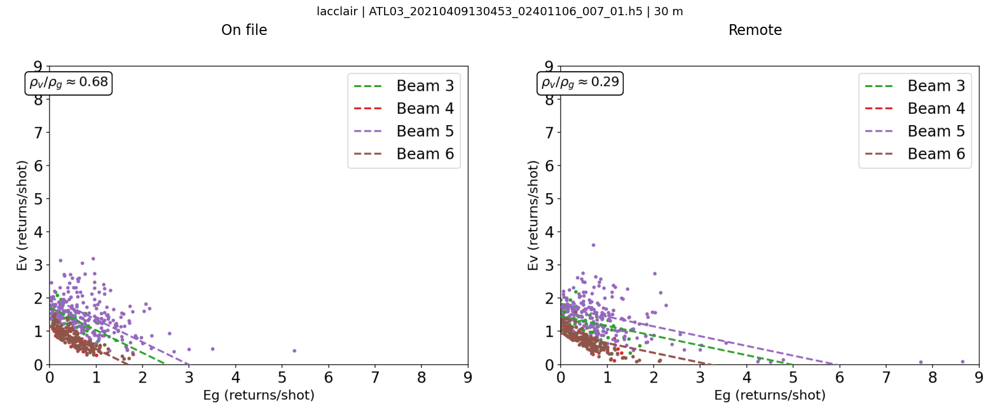


89: lacclair | ATL03_20210709084443_02401206_007_01.h5
Nothing to rebin for lacclair file 89's beam 1.
Failed to open ATL03 file for lacclair file 89's beam 2.
Nothing to rebin for lacclair file 89's beam 3.
Failed to open ATL03 file for lacclair file 89's beam 4.
Failed to open ATL03 file for lacclair file 89's beam 5.
Failed to open ATL03 file for lacclair file 89's beam 6.
lacclair: 1 overpasses
  ATL03_20210709084443_02401206_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



90: lacclair | ATL03_20210731192138_05831202_007_01.h5
Failed to open ATL03 file for lacclair file 90's beam 1.
Failed to open ATL03 file for lacclair file 90's beam 2.
Failed to open ATL03 file for lacclair file 90's beam 3.
Failed to open ATL03 file for lacclair file 90's beam 4.
Nothing to rebin for lacclair file 90's beam 5.
Nothing to rebin for lacclair file 90's beam 6.
lacclair: 1 overpasses
  ATL03_20210731192138_05831202_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,atmosphere_rejected,3783.0,0.0,0.0,0.0



91: lacclair | ATL03_20211030150137_05831302_007_01.h5
Nothing to rebin for lacclair file 91's beam 1.
Nothing to rebin for lacclair file 91's beam 2.
Nothing to rebin for lacclair file 91's beam 3.
Nothing to rebin for lacclair file 91's beam 4.
Nothing to rebin for lacclair file 91's beam 5.
Nothing to rebin for lacclair file 91's beam 6.
lacclair: 1 overpasses
  ATL03_20211030150137_05831302_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (6 outputs left out)

Beam 6 in lacclair file 94 has no data after filtering.
Beam 3, box 0 in lacclair file 94 has insufficient data.
lacclair: 1 overpasses
  ATL03_20220707152425_02401606_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,20711.0,71.0,3.0,0.0
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,ok,167196.0,265.0,7.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,ok,288005.0,247.0,1.0,0.0



95: lacclair | ATL03_20220828003726_10251602_007_01.h5
Failed to open ATL03 file for lacclair file 95's beam 3.
Failed to open ATL03 file for lacclair file 95's beam 4.
Failed to open ATL03 file for lacclair file 95's beam 5.
Failed to open ATL03 file for lacclair file 95's beam 6.
lacclair: 1 overpasses
  ATL03_20220828003726_10251602_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,3415.0,268.0,47.0,16.0
1,gt1r,ok,14328.0,242.0,89.0,21.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


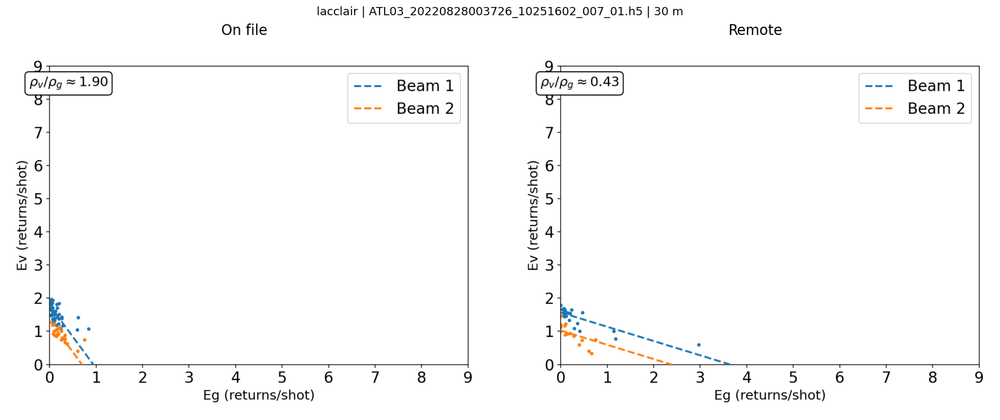


96: lacclair | ATL03_20221006110407_02401706_007_01.h5
Nothing to rebin for lacclair file 96's beam 1.
Nothing to rebin for lacclair file 96's beam 2.
Failed to open ATL03 file for lacclair file 96's beam 3.
Failed to open ATL03 file for lacclair file 96's beam 4.
Failed to open ATL03 file for lacclair file 96's beam 5.
Failed to open ATL03 file for lacclair file 96's beam 6.
lacclair: 1 overpasses
  ATL03_20221006110407_02401706_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



97: lacclair | ATL03_20221028214101_05831702_007_01.h5
Failed to open ATL03 file for lacclair file 97's beam 1.
Failed to open ATL03 file for lacclair file 97's beam 2.
Beam 3 in lacclair file 97 has no data after filtering.
Nothing to rebin for lacclair file 97's beam 4.
Beam 5 in lacclair file 97 has no data after filtering.
Beam 6 in lacclair file 97 has no data after filtering.
lacclair: 1 overpasses
  ATL03_20221028214101_05831702_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,ok,4186.0,80.0,2.0,0.0
4,gt3l,ok,1367.0,165.0,24.0,0.0
5,gt3r,ok,5916.0,268.0,88.0,0.0



98: lacclair | ATL03_20230127172052_05831802_007_01.h5
Failed to open ATL03 file for lacclair file 98's beam 1.
Failed to open ATL03 file for lacclair file 98's beam 2.
Failed to open ATL03 file for lacclair file 98's beam 3.
Failed to open ATL03 file for lacclair file 98's beam 4.
Nothing to rebin for lacclair file 98's beam 5.
Nothing to rebin for lacclair file 98's beam 6.
lacclair: 1 overpasses
  ATL03_20230127172052_05831802_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,atmosphere_rejected,4722.0,0.0,0.0,0.0
5,gt3r,atmosphere_rejected,24053.0,0.0,0.0,0.0


... (2 outputs left out)


100: lacclair | ATL03_20230527113627_10251902_007_01.h5
Failed to open ATL03 file for lacclair file 100's beam 1.
Failed to open ATL03 file for lacclair file 100's beam 2.
Failed to open ATL03 file for lacclair file 100's beam 3.
Failed to open ATL03 file for lacclair file 100's beam 4.
Nothing to rebin for lacclair file 100's beam 5.
Nothing to rebin for lacclair file 100's beam 6.
lacclair: 1 overpasses
  ATL03_20230527113627_10251902_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



101: lacclair | ATL03_20230705220302_02402006_007_01.h5
Failed to open ATL03 file for lacclair file 101's beam 1.
Failed to open ATL03 file for lacclair file 101's beam 2.
Failed to open ATL03 file for lacclair file 101's beam 3.
Failed to open ATL03 file for lacclair file 101's beam 4.
Beam 6, box 0 in lacclair file 101 has insufficient data.
lacclair: 1 overpasses
  ATL03_20230705220302_02402006_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,atmosphere_rejected,24306.0,59.0,1.0,0.0
1,gt1r,atmosphere_rejected,13059.0,28.0,0.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


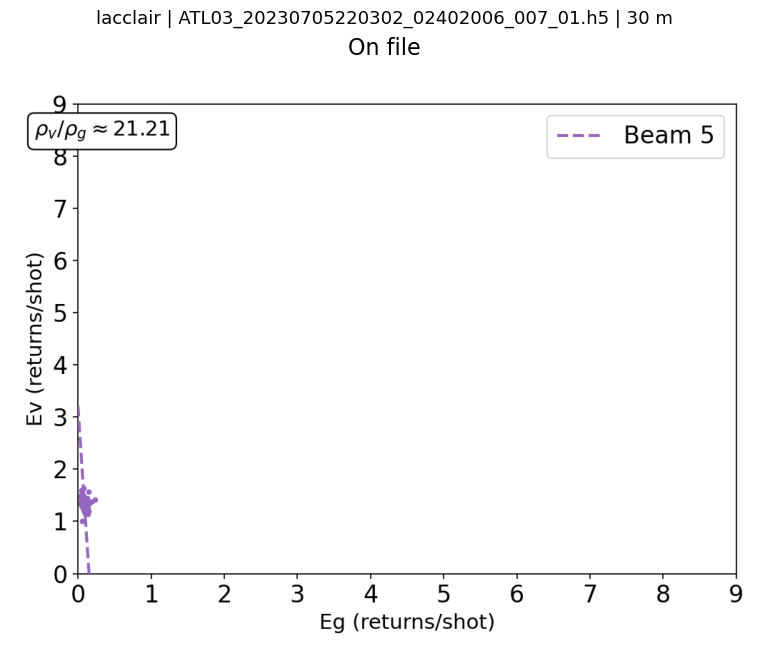


102: lacclair | ATL03_20230728083945_05832002_007_01.h5
Nothing to rebin for lacclair file 102's beam 1.
Nothing to rebin for lacclair file 102's beam 2.
Nothing to rebin for lacclair file 102's beam 3.
Nothing to rebin for lacclair file 102's beam 4.
Failed to open ATL03 file for lacclair file 102's beam 5.
Failed to open ATL03 file for lacclair file 102's beam 6.
lacclair: 1 overpasses
  ATL03_20230728083945_05832002_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



103: lacclair | ATL03_20231004174232_02402106_007_01.h5
Failed to open ATL03 file for lacclair file 103's beam 1.
Failed to open ATL03 file for lacclair file 103's beam 2.
Failed to open ATL03 file for lacclair file 103's beam 3.
Failed to open ATL03 file for lacclair file 103's beam 4.
Beam 5 in lacclair file 103 has no data after filtering.
Beam 6 in lacclair file 103 has no data after filtering.
lacclair: 1 overpasses
  ATL03_20231004174232_02402106_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,77710.0,269.0,38.0,0.0
1,gt1r,ok,16680.0,83.0,5.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



104: lacclair | ATL03_20231027041931_05832102_007_01.h5
Nothing to rebin for lacclair file 104's beam 1.
Failed to open ATL03 file for lacclair file 104's beam 2.
Failed to open ATL03 file for lacclair file 104's beam 3.
Failed to open ATL03 file for lacclair file 104's beam 4.
Failed to open ATL03 file for lacclair file 104's beam 5.
Failed to open ATL03 file for lacclair file 104's beam 6.
lacclair: 1 overpasses
  ATL03_20231027041931_05832102_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (2 outputs left out)


106: lacclair | ATL03_20240125235850_05832202_007_01.h5
Failed to open ATL03 file for lacclair file 106's beam 1.
Failed to open ATL03 file for lacclair file 106's beam 2.
Failed to open ATL03 file for lacclair file 106's beam 3.
Failed to open ATL03 file for lacclair file 106's beam 4.
Nothing to rebin for lacclair file 106's beam 5.
Nothing to rebin for lacclair file 106's beam 6.
lacclair: 1 overpasses
  ATL03_20240125235850_05832202_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



107: lacclair | ATL03_20240403090132_02402306_007_01.h5
Failed to open ATL03 file for lacclair file 107's beam 5.
Failed to open ATL03 file for lacclair file 107's beam 6.
lacclair: 1 overpasses
  ATL03_20240403090132_02402306_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,10743.0,269.0,223.0,146.0
1,gt1r,ok,44319.0,268.0,268.0,157.0
2,gt2l,ok,11603.0,221.0,180.0,82.0
3,gt2r,ok,39966.0,189.0,166.0,92.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


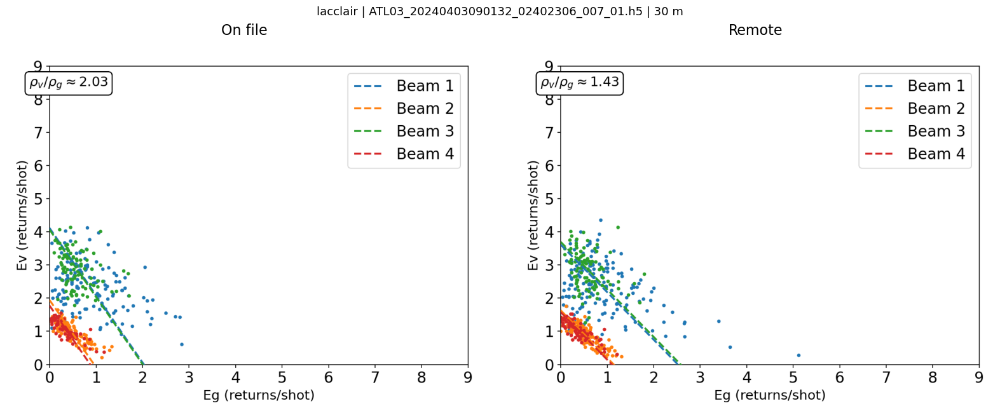


108: lacclair | ATL03_20240425193819_05832302_007_01.h5
Failed to open ATL03 file for lacclair file 108's beam 1.
Failed to open ATL03 file for lacclair file 108's beam 2.
Failed to open ATL03 file for lacclair file 108's beam 3.
Failed to open ATL03 file for lacclair file 108's beam 4.
Nothing to rebin for lacclair file 108's beam 5.
Nothing to rebin for lacclair file 108's beam 6.
lacclair: 1 overpasses
  ATL03_20240425193819_05832302_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



109: lacclair | ATL03_20240703044119_02402406_007_01.h5
Nothing to rebin for lacclair file 109's beam 1.
Nothing to rebin for lacclair file 109's beam 2.
lacclair: 1 overpasses
  ATL03_20240703044119_02402406_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,15497.0,268.0,90.0,10.0
1,gt1r,ok,3917.0,268.0,39.0,7.0
2,gt2l,ok,17451.0,268.0,102.0,30.0
3,gt2r,ok,4573.0,268.0,39.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


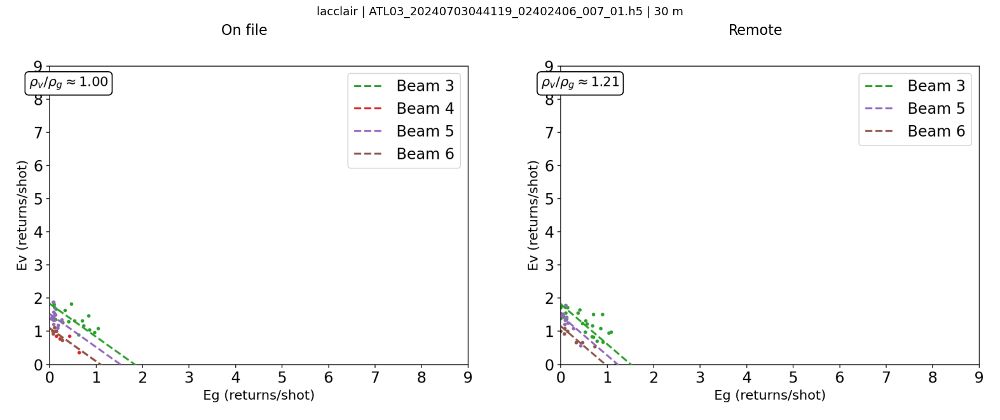


110: lacclair | ATL03_20240823135405_10252402_007_01.h5
Failed to open ATL03 file for lacclair file 110's beam 1.
Failed to open ATL03 file for lacclair file 110's beam 2.
Failed to open ATL03 file for lacclair file 110's beam 3.
Failed to open ATL03 file for lacclair file 110's beam 4.
Nothing to rebin for lacclair file 110's beam 5.
Failed to open ATL03 file for lacclair file 110's beam 6.
lacclair: 1 overpasses
  ATL03_20240823135405_10252402_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



111: lacclair | ATL03_20241002002050_02402506_007_01.h5
Failed to open ATL03 file for lacclair file 111's beam 1.
Failed to open ATL03 file for lacclair file 111's beam 2.
Failed to open ATL03 file for lacclair file 111's beam 3.
Failed to open ATL03 file for lacclair file 111's beam 4.
Failed to open ATL03 file for lacclair file 111's beam 5.
Failed to open ATL03 file for lacclair file 111's beam 6.
lacclair: 1 overpasses
  ATL03_20241002002050_02402506_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



112: lacclair | ATL03_20241024105738_05832502_007_01.h5
Nothing to rebin for lacclair file 112's beam 1.
Nothing to rebin for lacclair file 112's beam 2.
Failed to open ATL03 file for lacclair file 112's beam 3.
Failed to open ATL03 file for lacclair file 112's beam 4.
Failed to open ATL03 file for lacclair file 112's beam 5.
Failed to open ATL03 file for lacclair file 112's beam 6.
lacclair: 1 overpasses
  ATL03_20241024105738_05832502_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (30 outputs left out)


128: marcell_MN | ATL03_20200502065232_05610706_007_01.h5
Failed to open ATL03 file for marcell_MN file 128's beam 1.
Failed to open ATL03 file for marcell_MN file 128's beam 2.
Nothing to rebin for marcell_MN file 128's beam 3.
Nothing to rebin for marcell_MN file 128's beam 4.
Beam 5 in marcell_MN file 128 has no data after filtering.
Beam 6 in marcell_MN file 128 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20200502065232_05610706_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,ok,13211.0,143.0,22.0,0.0



129: marcell_MN | ATL03_20200622160526_13460702_007_01.h5
Nothing to rebin for marcell_MN file 129's beam 6.
marcell_MN: 1 overpasses
  ATL03_20200622160526_13460702_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,80724.0,253.0,29.0,26.0
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,71916.0,265.0,101.0,95.0
3,gt2r,ok,23873.0,196.0,31.0,27.0
4,gt3l,ok,100041.0,226.0,54.0,29.0
5,gt3r,ok,25058.0,121.0,6.0,6.0


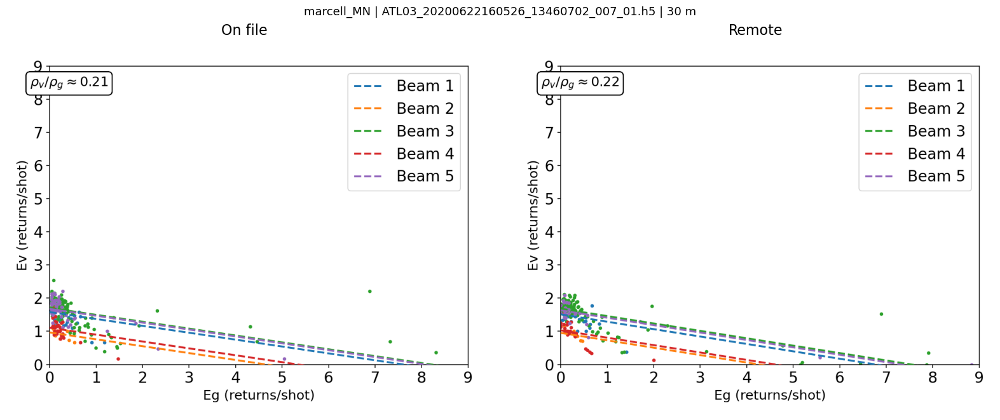


130: marcell_MN | ATL03_20200801023220_05610806_007_01.h5
Beam 1 in marcell_MN file 130 has no data after filtering.
Beam 2 in marcell_MN file 130 has no data after filtering.
Beam 3 in marcell_MN file 130 has no data after filtering.
Beam 4 in marcell_MN file 130 has no data after filtering.
Beam 5 in marcell_MN file 130 has no data after filtering.
Beam 6 in marcell_MN file 130 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20200801023220_05610806_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,35167,268,195,0
1,gt1r,ok,8132,268,94,0
2,gt2l,ok,92402,264,59,0
3,gt2r,ok,15797,232,33,0
4,gt3l,ok,35727,197,84,0
5,gt3r,ok,7639,164,14,0



131: marcell_MN | ATL03_20200921114515_13460802_007_01.h5
Failed to open ATL03 file for marcell_MN file 131's beam 1.
Failed to open ATL03 file for marcell_MN file 131's beam 2.
Failed to open ATL03 file for marcell_MN file 131's beam 3.
Failed to open ATL03 file for marcell_MN file 131's beam 4.
Beam 5 in marcell_MN file 131 has no data after filtering.
Beam 6 in marcell_MN file 131 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20200921114515_13460802_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,41173.0,177.0,100.0,0.0
1,gt1r,ok,8432.0,146.0,37.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



132: marcell_MN | ATL03_20201030221209_05610906_007_01.h5
Nothing to rebin for marcell_MN file 132's beam 5.
Nothing to rebin for marcell_MN file 132's beam 6.
marcell_MN: 1 overpasses
  ATL03_20201030221209_05610906_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,38226.0,269.0,117.0,32.0
3,gt2r,ok,15825.0,268.0,68.0,31.0
4,gt3l,ok,52833.0,268.0,193.0,134.0
5,gt3r,ok,17394.0,268.0,91.0,48.0


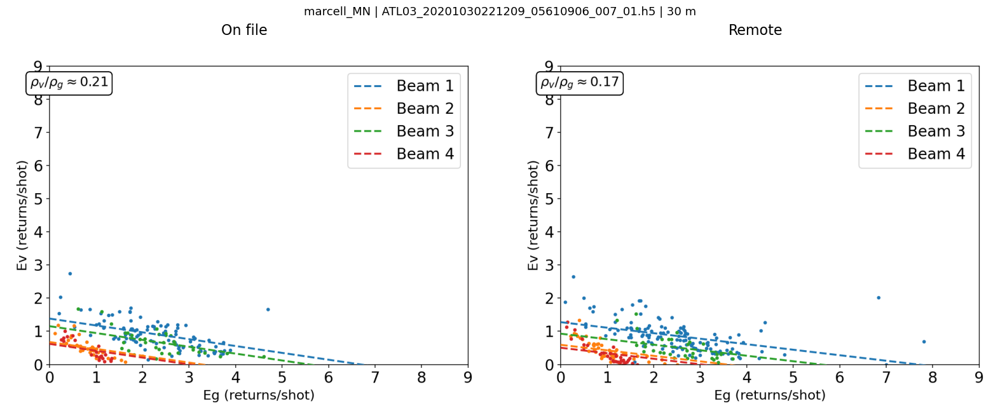


133: marcell_MN | ATL03_20201221072506_13460902_007_01.h5
Failed to open ATL03 file for marcell_MN file 133's beam 1.
Failed to open ATL03 file for marcell_MN file 133's beam 2.
Failed to open ATL03 file for marcell_MN file 133's beam 3.
Failed to open ATL03 file for marcell_MN file 133's beam 4.
Failed to open ATL03 file for marcell_MN file 133's beam 5.
Failed to open ATL03 file for marcell_MN file 133's beam 6.
marcell_MN: 1 overpasses
  ATL03_20201221072506_13460902_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



134: marcell_MN | ATL03_20210129175203_05611006_007_01.h5
Nothing to rebin for marcell_MN file 134's beam 1.
Nothing to rebin for marcell_MN file 134's beam 2.
Failed to open ATL03 file for marcell_MN file 134's beam 3.
Failed to open ATL03 file for marcell_MN file 134's beam 4.
Failed to open ATL03 file for marcell_MN file 134's beam 5.
Failed to open ATL03 file for marcell_MN file 134's beam 6.
marcell_MN: 1 overpasses
  ATL03_20210129175203_05611006_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



135: marcell_MN | ATL03_20210221042856_09041002_007_01.h5
Failed to open ATL03 file for marcell_MN file 135's beam 1.
Failed to open ATL03 file for marcell_MN file 135's beam 2.
Failed to open ATL03 file for marcell_MN file 135's beam 3.
Failed to open ATL03 file for marcell_MN file 135's beam 4.
Beam 5 in marcell_MN file 135 has no data after filtering.
Nothing to rebin for marcell_MN file 135's beam 6.
marcell_MN: 1 overpasses
  ATL03_20210221042856_09041002_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,atmosphere_rejected,1717.0,62.0,0.0,0.0



136: marcell_MN | ATL03_20210430133152_05611106_007_01.h5
Failed to open ATL03 file for marcell_MN file 136's beam 1.
Failed to open ATL03 file for marcell_MN file 136's beam 2.
Failed to open ATL03 file for marcell_MN file 136's beam 3.
Failed to open ATL03 file for marcell_MN file 136's beam 4.
marcell_MN: 1 overpasses
  ATL03_20210430133152_05611106_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,16703.0,268.0,124.0,121.0
5,gt3r,ok,39234.0,269.0,201.0,201.0


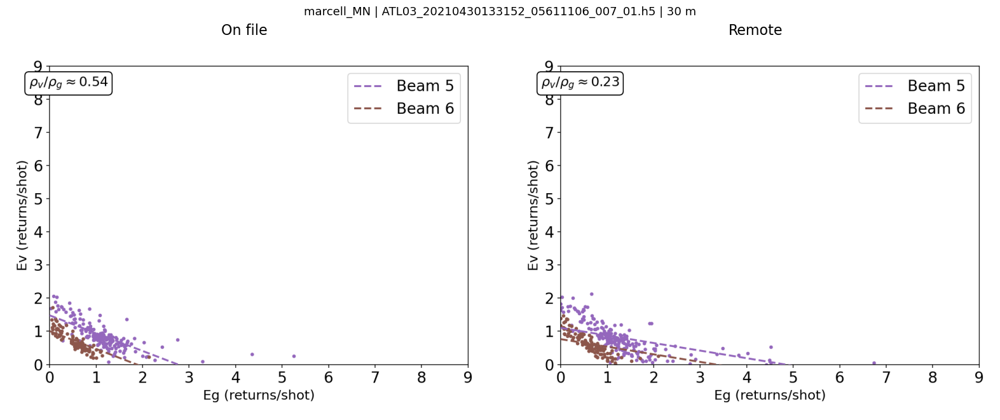


137: marcell_MN | ATL03_20210620224448_13461102_007_01.h5
Nothing to rebin for marcell_MN file 137's beam 1.
Nothing to rebin for marcell_MN file 137's beam 2.
Nothing to rebin for marcell_MN file 137's beam 3.
Nothing to rebin for marcell_MN file 137's beam 4.
Nothing to rebin for marcell_MN file 137's beam 5.
Nothing to rebin for marcell_MN file 137's beam 6.
marcell_MN: 1 overpasses
  ATL03_20210620224448_13461102_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



138: marcell_MN | ATL03_20210730091146_05611206_007_01.h5
Beam 1 in marcell_MN file 138 has no data after filtering.
Beam 2 in marcell_MN file 138 has no data after filtering.
Beam 3 in marcell_MN file 138 has no data after filtering.
Beam 4 in marcell_MN file 138 has no data after filtering.
Beam 5 in marcell_MN file 138 has no data after filtering.
Beam 6 in marcell_MN file 138 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20210730091146_05611206_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,ok,13225.0,164.0,6.0,0.0



139: marcell_MN | ATL03_20210919182445_13461202_007_01.h5
Nothing to rebin for marcell_MN file 139's beam 3.
Nothing to rebin for marcell_MN file 139's beam 4.
Failed to open ATL03 file for marcell_MN file 139's beam 5.
Failed to open ATL03 file for marcell_MN file 139's beam 6.
marcell_MN: 1 overpasses
  ATL03_20210919182445_13461202_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,21944.0,269.0,124.0,111.0
1,gt1r,ok,35623.0,268.0,194.0,189.0
2,gt2l,atmosphere_rejected,1311.0,0.0,0.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


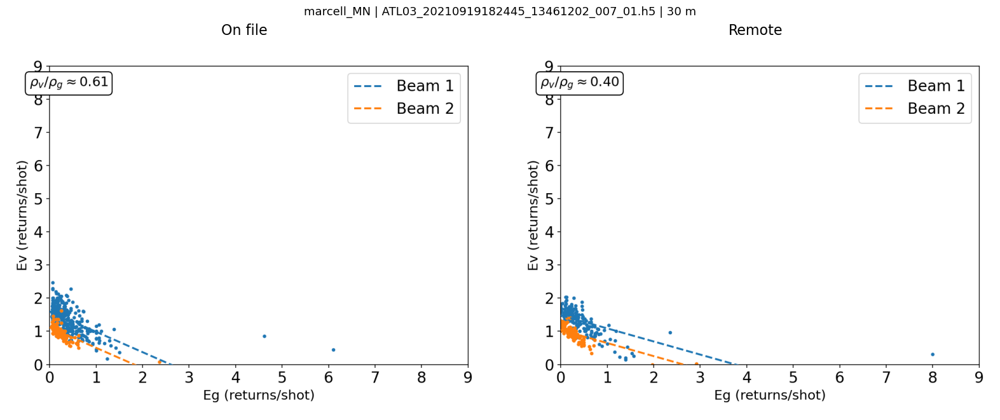


140: marcell_MN | ATL03_20211029045144_05611306_007_01.h5
Failed to open ATL03 file for marcell_MN file 140's beam 1.
Failed to open ATL03 file for marcell_MN file 140's beam 2.
Nothing to rebin for marcell_MN file 140's beam 3.
Failed to open ATL03 file for marcell_MN file 140's beam 4.
Nothing to rebin for marcell_MN file 140's beam 5.
Failed to open ATL03 file for marcell_MN file 140's beam 6.
marcell_MN: 1 overpasses
  ATL03_20211029045144_05611306_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



141: marcell_MN | ATL03_20211120152840_09041302_007_01.h5
Failed to open ATL03 file for marcell_MN file 141's beam 3.
Failed to open ATL03 file for marcell_MN file 141's beam 4.
Failed to open ATL03 file for marcell_MN file 141's beam 5.
Failed to open ATL03 file for marcell_MN file 141's beam 6.
marcell_MN: 1 overpasses
  ATL03_20211120152840_09041302_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,70133.0,268.0,130.0,130.0
5,gt3r,ok,27056.0,268.0,73.0,73.0


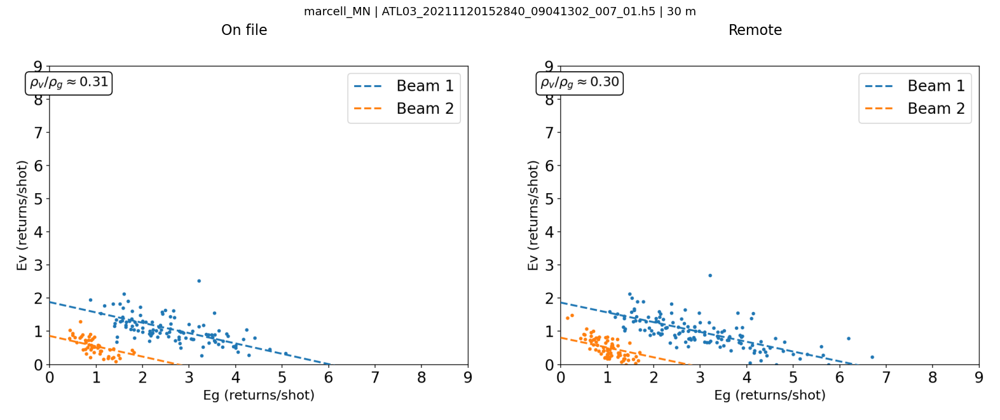


142: marcell_MN | ATL03_20220128003134_05611406_007_01.h5
Failed to open ATL03 file for marcell_MN file 142's beam 1.
Failed to open ATL03 file for marcell_MN file 142's beam 2.
Failed to open ATL03 file for marcell_MN file 142's beam 3.
Failed to open ATL03 file for marcell_MN file 142's beam 4.
Failed to open ATL03 file for marcell_MN file 142's beam 5.
Failed to open ATL03 file for marcell_MN file 142's beam 6.
marcell_MN: 1 overpasses
  ATL03_20220128003134_05611406_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



143: marcell_MN | ATL03_20220320094433_13461402_007_01.h5
Failed to open ATL03 file for marcell_MN file 143's beam 1.
Failed to open ATL03 file for marcell_MN file 143's beam 2.
Nothing to rebin for marcell_MN file 143's beam 3.
Nothing to rebin for marcell_MN file 143's beam 4.
marcell_MN: 1 overpasses
  ATL03_20220320094433_13461402_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,57468.0,269.0,204.0,204.0
1,gt1r,ok,13758.0,268.0,147.0,143.0
2,gt2l,atmosphere_rejected,3388.0,0.0,0.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


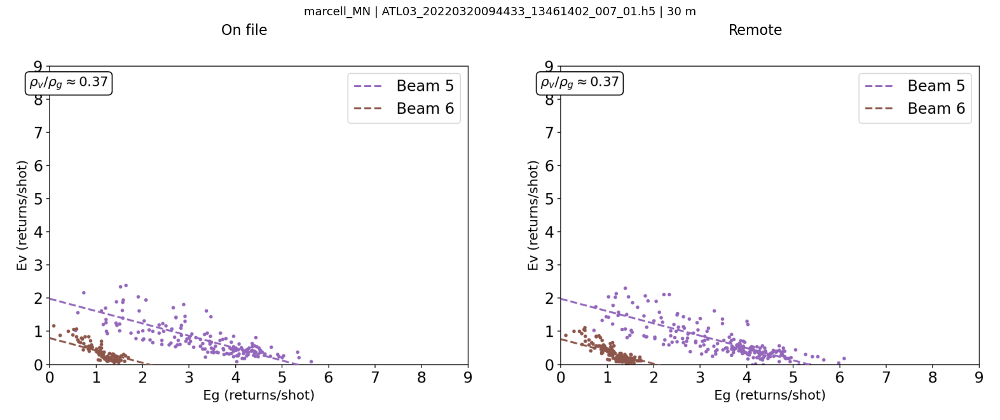


144: marcell_MN | ATL03_20220619052426_13461502_007_01.h5
Failed to open ATL03 file for marcell_MN file 144's beam 1.
Failed to open ATL03 file for marcell_MN file 144's beam 2.
Beam 3 in marcell_MN file 144 has no data after filtering.
Nothing to rebin for marcell_MN file 144's beam 4.
Beam 5 in marcell_MN file 144 has no data after filtering.
Beam 6 in marcell_MN file 144 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20220619052426_13461502_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



145: marcell_MN | ATL03_20220728155124_05611606_007_01.h5
Failed to open ATL03 file for marcell_MN file 145's beam 1.
Failed to open ATL03 file for marcell_MN file 145's beam 2.
Nothing to rebin for marcell_MN file 145's beam 3.
Nothing to rebin for marcell_MN file 145's beam 4.
marcell_MN: 1 overpasses
  ATL03_20220728155124_05611606_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,atmosphere_rejected,6475.0,6.0,0.0,0.0
3,gt2r,atmosphere_rejected,37110.0,75.0,0.0,0.0
4,gt3l,ok,23806.0,121.0,7.0,3.0
5,gt3r,ok,74997.0,215.0,52.0,27.0


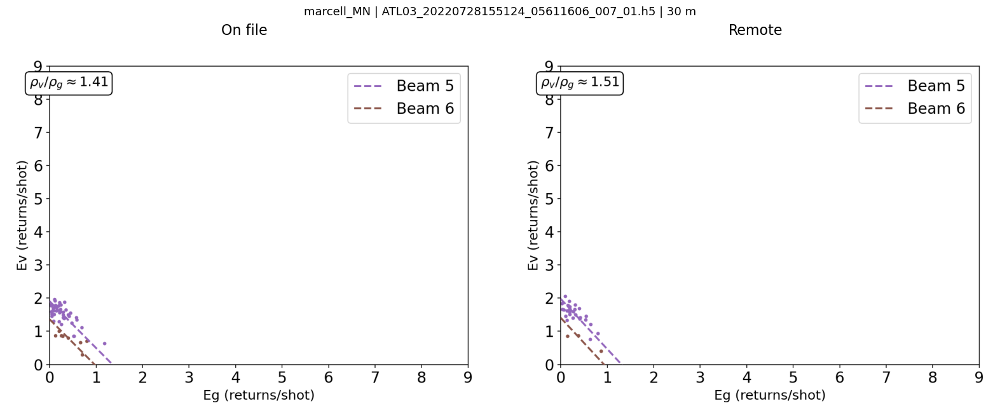


146: marcell_MN | ATL03_20220918010421_13461602_007_01.h5
Nothing to rebin for marcell_MN file 146's beam 1.
Nothing to rebin for marcell_MN file 146's beam 2.
Beam 3 in marcell_MN file 146 has no data after filtering.
Beam 4 in marcell_MN file 146 has no data after filtering.
Nothing to rebin for marcell_MN file 146's beam 5.
Nothing to rebin for marcell_MN file 146's beam 6.
marcell_MN: 1 overpasses
  ATL03_20220918010421_13461602_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



147: marcell_MN | ATL03_20221027113110_05611706_007_01.h5
Beam 1 in marcell_MN file 147 has no data after filtering.
Beam 2 in marcell_MN file 147 has no data after filtering.
Beam 3 in marcell_MN file 147 has no data after filtering.
Beam 4 in marcell_MN file 147 has no data after filtering.
Beam 5 in marcell_MN file 147 has no data after filtering.
Beam 6 in marcell_MN file 147 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20221027113110_05611706_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,ok,9361.0,269.0,105.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,ok,31417.0,268.0,55.0,0.0
4,gt3l,ok,5078.0,196.0,4.0,0.0
5,gt3r,ok,21276.0,166.0,74.0,0.0



148: marcell_MN | ATL03_20221217204359_13461702_007_01.h5
Nothing to rebin for marcell_MN file 148's beam 1.
Nothing to rebin for marcell_MN file 148's beam 2.
Failed to open ATL03 file for marcell_MN file 148's beam 3.
Failed to open ATL03 file for marcell_MN file 148's beam 4.
Failed to open ATL03 file for marcell_MN file 148's beam 5.
Failed to open ATL03 file for marcell_MN file 148's beam 6.
marcell_MN: 1 overpasses
  ATL03_20221217204359_13461702_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



149: marcell_MN | ATL03_20230126071107_05611806_007_01.h5
marcell_MN: 1 overpasses
  ATL03_20230126071107_05611806_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,23858,268,160,157
1,gt1r,ok,94579,268,215,208
2,gt2l,ok,22750,269,143,143
3,gt2r,ok,75048,269,197,197
4,gt3l,ok,24507,198,83,75
5,gt3r,ok,97316,168,138,131


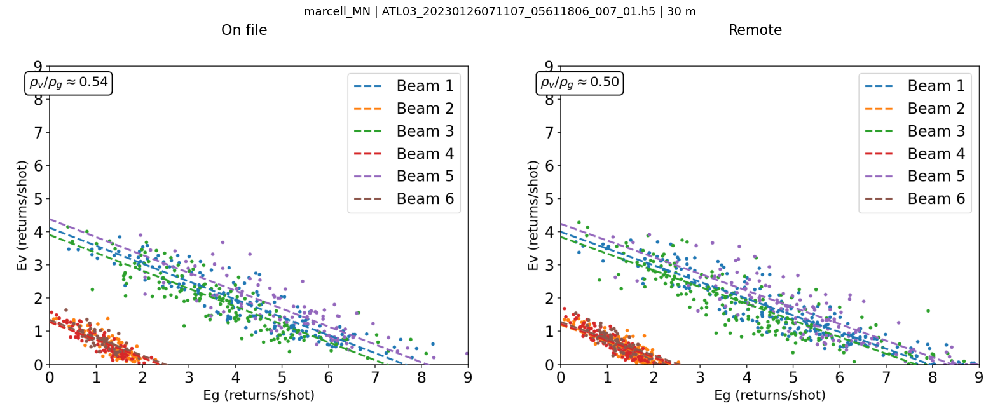


150: marcell_MN | ATL03_20230318162359_13461802_007_01.h5
Failed to open ATL03 file for marcell_MN file 150's beam 1.
Failed to open ATL03 file for marcell_MN file 150's beam 2.
Nothing to rebin for marcell_MN file 150's beam 3.
Nothing to rebin for marcell_MN file 150's beam 4.
marcell_MN: 1 overpasses
  ATL03_20230318162359_13461802_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,135929.0,269.0,114.0,22.0
1,gt1r,ok,76323.0,268.0,192.0,53.0
2,gt2l,atmosphere_rejected,7526.0,0.0,0.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


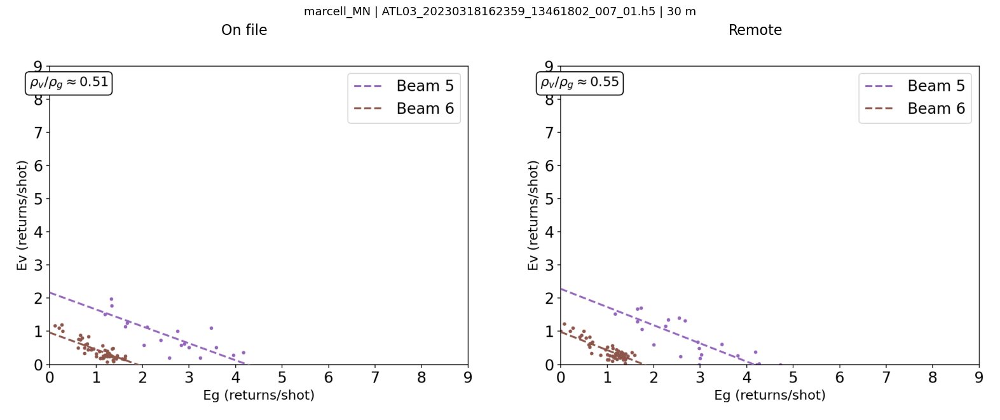


151: marcell_MN | ATL03_20230617120315_13461902_007_01.h5
Nothing to rebin for marcell_MN file 151's beam 1.
Nothing to rebin for marcell_MN file 151's beam 2.
Nothing to rebin for marcell_MN file 151's beam 3.
Nothing to rebin for marcell_MN file 151's beam 4.
Nothing to rebin for marcell_MN file 151's beam 5.
Nothing to rebin for marcell_MN file 151's beam 6.
marcell_MN: 1 overpasses
  ATL03_20230617120315_13461902_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



152: marcell_MN | ATL03_20230726222952_05612006_007_01.h5
Failed to open ATL03 file for marcell_MN file 152's beam 1.
Failed to open ATL03 file for marcell_MN file 152's beam 2.
marcell_MN: 1 overpasses
  ATL03_20230726222952_05612006_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,47863.0,268.0,125.0,122.0
1,gt1r,ok,21692.0,265.0,40.0,36.0
2,gt2l,ok,36505.0,268.0,141.0,141.0
3,gt2r,ok,17983.0,250.0,71.0,54.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


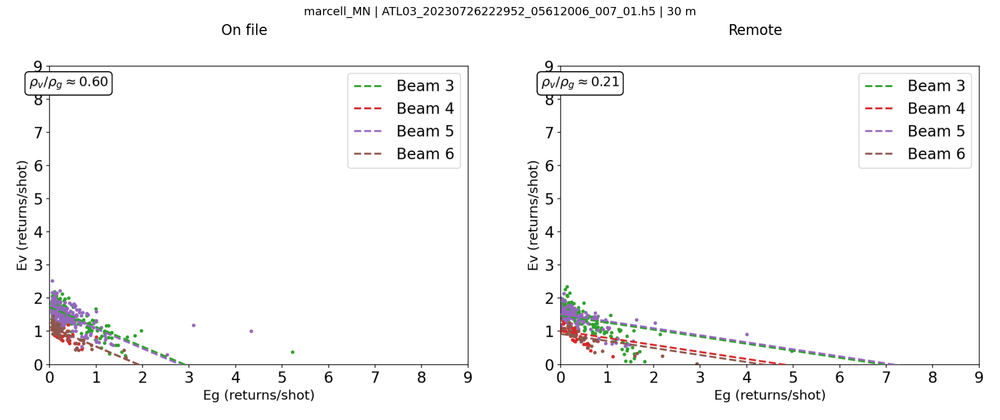


153: marcell_MN | ATL03_20230916074237_13462002_007_01.h5
Failed to open ATL03 file for marcell_MN file 153's beam 1.
Failed to open ATL03 file for marcell_MN file 153's beam 2.
Nothing to rebin for marcell_MN file 153's beam 3.
Nothing to rebin for marcell_MN file 153's beam 4.
Nothing to rebin for marcell_MN file 153's beam 5.
Failed to open ATL03 file for marcell_MN file 153's beam 6.
marcell_MN: 1 overpasses
  ATL03_20230916074237_13462002_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



154: marcell_MN | ATL03_20231025180931_05612106_007_01.h5
Nothing to rebin for marcell_MN file 154's beam 1.
Nothing to rebin for marcell_MN file 154's beam 2.
Nothing to rebin for marcell_MN file 154's beam 3.
Nothing to rebin for marcell_MN file 154's beam 4.
Nothing to rebin for marcell_MN file 154's beam 5.
Nothing to rebin for marcell_MN file 154's beam 6.
marcell_MN: 1 overpasses
  ATL03_20231025180931_05612106_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



155: marcell_MN | ATL03_20231216032224_13462102_007_01.h5
Nothing to rebin for marcell_MN file 155's beam 1.
Failed to open ATL03 file for marcell_MN file 155's beam 2.
Nothing to rebin for marcell_MN file 155's beam 3.
Failed to open ATL03 file for marcell_MN file 155's beam 4.
Failed to open ATL03 file for marcell_MN file 155's beam 5.
Failed to open ATL03 file for marcell_MN file 155's beam 6.
marcell_MN: 1 overpasses
  ATL03_20231216032224_13462102_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



156: marcell_MN | ATL03_20240315230134_13462202_007_01.h5
Nothing to rebin for marcell_MN file 156's beam 1.
Nothing to rebin for marcell_MN file 156's beam 2.
Nothing to rebin for marcell_MN file 156's beam 3.
Nothing to rebin for marcell_MN file 156's beam 4.
Failed to open ATL03 file for marcell_MN file 156's beam 5.
Failed to open ATL03 file for marcell_MN file 156's beam 6.
marcell_MN: 1 overpasses
  ATL03_20240315230134_13462202_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



157: marcell_MN | ATL03_20240424092826_05612306_007_01.h5
Beam 3 in marcell_MN file 157 has no data after filtering.
Beam 4 in marcell_MN file 157 has no data after filtering.
Beam 5 in marcell_MN file 157 has no data after filtering.
Beam 6 in marcell_MN file 157 has no data after filtering.
marcell_MN: 1 overpasses
  ATL03_20240424092826_05612306_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,8767,268,60,12
1,gt1r,ok,32655,268,154,33
2,gt2l,ok,15544,269,31,0
3,gt2r,ok,48536,269,153,0
4,gt3l,ok,8899,190,59,0
5,gt3r,ok,38088,161,101,0


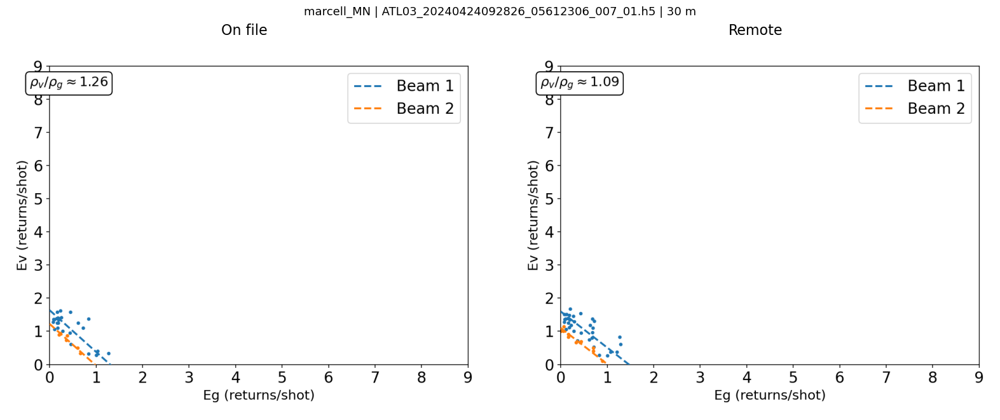


158: marcell_MN | ATL03_20240724050807_05612406_007_01.h5
Beam 1 in marcell_MN file 158 has no data after filtering.
Beam 2 in marcell_MN file 158 has no data after filtering.
Beam 3 in marcell_MN file 158 has no data after filtering.
Beam 4 in marcell_MN file 158 has no data after filtering.
Nothing to rebin for marcell_MN file 158's beam 5.
Nothing to rebin for marcell_MN file 158's beam 6.
marcell_MN: 1 overpasses
  ATL03_20240724050807_05612406_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,12856.0,223.0,49.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,11948.0,206.0,48.0,0.0
5,gt3r,ok,3414.0,168.0,3.0,0.0



159: marcell_MN | ATL03_20240913142104_13462402_007_01.h5
Nothing to rebin for marcell_MN file 159's beam 1.
Nothing to rebin for marcell_MN file 159's beam 2.
marcell_MN: 1 overpasses
  ATL03_20240913142104_13462402_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,43419.0,269.0,121.0,118.0
1,gt1r,ok,19114.0,268.0,46.0,43.0
2,gt2l,ok,41916.0,268.0,74.0,62.0
3,gt2r,ok,18813.0,268.0,26.0,14.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


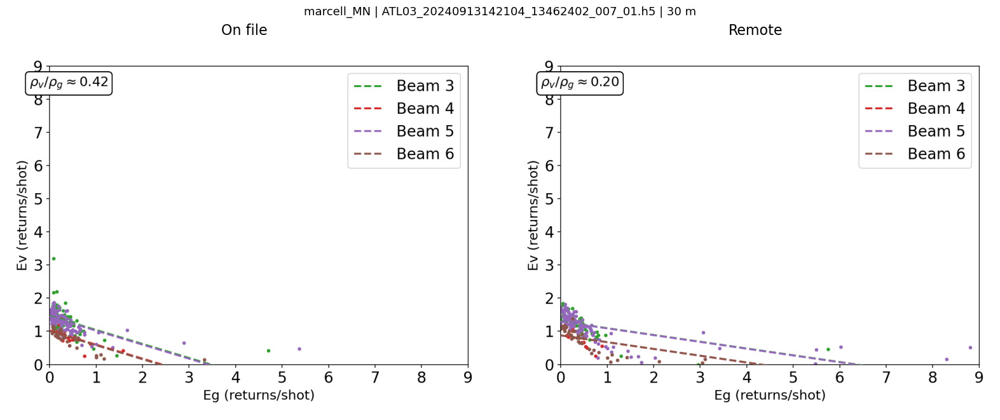


160: marcell_MN | ATL03_20241023004750_05612506_007_01.h5
Failed to open ATL03 file for marcell_MN file 160's beam 1.
Failed to open ATL03 file for marcell_MN file 160's beam 2.
Failed to open ATL03 file for marcell_MN file 160's beam 3.
Failed to open ATL03 file for marcell_MN file 160's beam 4.
Failed to open ATL03 file for marcell_MN file 160's beam 5.
Failed to open ATL03 file for marcell_MN file 160's beam 6.
marcell_MN: 1 overpasses
  ATL03_20241023004750_05612506_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



161: marcell_MN | ATL03_20250121202718_05612606_007_01.h5
Nothing to rebin for marcell_MN file 161's beam 1.
Nothing to rebin for marcell_MN file 161's beam 2.
Nothing to rebin for marcell_MN file 161's beam 3.
Nothing to rebin for marcell_MN file 161's beam 4.
Nothing to rebin for marcell_MN file 161's beam 5.
Nothing to rebin for marcell_MN file 161's beam 6.
marcell_MN: 1 overpasses
  ATL03_20250121202718_05612606_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



162: sodankyla_full | ATL03_20181014020411_02360105_007_01.h5
Failed to open ATL03 file for sodankyla_full file 162's beam 1.
Failed to open ATL03 file for sodankyla_full file 162's beam 2.
Nothing to rebin for sodankyla_full file 162's beam 3.
Nothing to rebin for sodankyla_full file 162's beam 4.
Nothing to rebin for sodankyla_full file 162's beam 5.
Nothing to rebin for sodankyla_full file 162's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20181014020411_02360105_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (12 outputs left out)


169: sodankyla_full | ATL03_20190327053800_13560203_007_01.h5
Beam 1 in sodankyla_full file 169 has no data after filtering.
Nothing to rebin for sodankyla_full file 169's beam 2.
Nothing to rebin for sodankyla_full file 169's beam 3.
Nothing to rebin for sodankyla_full file 169's beam 4.
Failed to open ATL03 file for sodankyla_full file 169's beam 5.
Failed to open ATL03 file for sodankyla_full file 169's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20190327053800_13560203_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,40754.0,270.0,24.0,0.0
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



170: sodankyla_full | ATL03_20190413172354_02360305_007_01.h5
Failed to open ATL03 file for sodankyla_full file 170's beam 5.
Failed to open ATL03 file for sodankyla_full file 170's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20190413172354_02360305_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,17206.0,16.0,7.0,7.0
3,gt2r,ok,7406.0,43.0,17.0,17.0
4,gt3l,ok,57649.0,270.0,26.0,26.0
5,gt3r,ok,17223.0,269.0,14.0,14.0


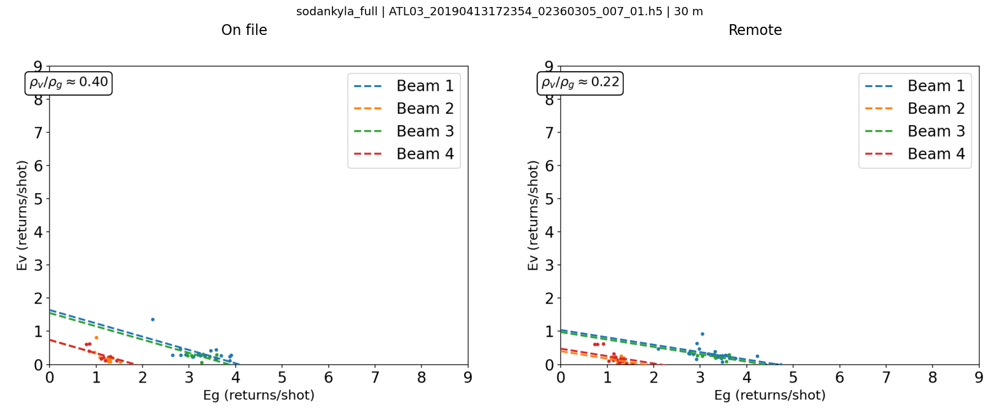


171: sodankyla_full | ATL03_20190425041400_04110303_007_01.h5
Failed to open ATL03 file for sodankyla_full file 171's beam 1.
Failed to open ATL03 file for sodankyla_full file 171's beam 2.
Nothing to rebin for sodankyla_full file 171's beam 3.
Nothing to rebin for sodankyla_full file 171's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20190425041400_04110303_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,92861.0,270.0,33.0,33.0
1,gt1r,ok,42713.0,270.0,19.0,19.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


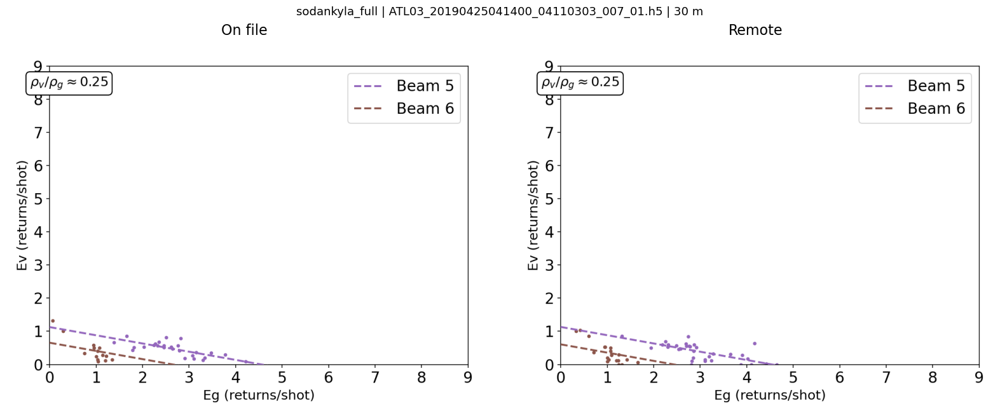


172: sodankyla_full | ATL03_20190614142731_11810305_007_02.h5
Failed to open ATL03 file for sodankyla_full file 172's beam 1.
Failed to open ATL03 file for sodankyla_full file 172's beam 2.
Failed to open ATL03 file for sodankyla_full file 172's beam 3.
Failed to open ATL03 file for sodankyla_full file 172's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20190614142731_11810305_007_02.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,39393.0,270.0,205.0,193.0
1,gt1r,ok,22712.0,265.0,209.0,201.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


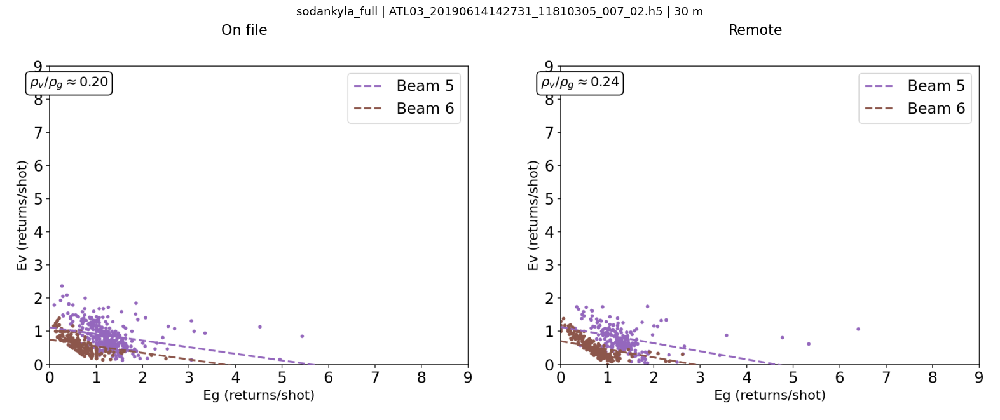


173: sodankyla_full | ATL03_20190626011737_13560303_007_01.h5


/scratch/s1803229/.conda/envs/snow_env/lib/python3.11/site-packages/scipy/interpolate/_interpolate.py:701: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


Beam 1 in sodankyla_full file 173 has no data after filtering.
Nothing to rebin for sodankyla_full file 173's beam 2.
Nothing to rebin for sodankyla_full file 173's beam 3.
Nothing to rebin for sodankyla_full file 173's beam 4.
Failed to open ATL03 file for sodankyla_full file 173's beam 5.
Failed to open ATL03 file for sodankyla_full file 173's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20190626011737_13560303_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



174: sodankyla_full | ATL03_20190713130322_02360405_007_01.h5
Nothing to rebin for sodankyla_full file 174's beam 1.
Nothing to rebin for sodankyla_full file 174's beam 2.
Failed to open ATL03 file for sodankyla_full file 174's beam 3.
Failed to open ATL03 file for sodankyla_full file 174's beam 4.
Failed to open ATL03 file for sodankyla_full file 174's beam 5.
Failed to open ATL03 file for sodankyla_full file 174's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20190713130322_02360405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (12 outputs left out)


181: sodankyla_full | ATL03_20200122151319_04110603_007_01.h5
Nothing to rebin for sodankyla_full file 181's beam 1.
Nothing to rebin for sodankyla_full file 181's beam 2.
Failed to open ATL03 file for sodankyla_full file 181's beam 3.
Failed to open ATL03 file for sodankyla_full file 181's beam 4.
Failed to open ATL03 file for sodankyla_full file 181's beam 5.
Failed to open ATL03 file for sodankyla_full file 181's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20200122151319_04110603_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,atmosphere_rejected,3187.0,0.0,0.0,0.0
1,gt1r,atmosphere_rejected,4501.0,0.0,0.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



182: sodankyla_full | ATL03_20200324121701_13560603_007_01.h5
Failed to open ATL03 file for sodankyla_full file 182's beam 1.
Failed to open ATL03 file for sodankyla_full file 182's beam 2.
sodankyla_full: 1 overpasses
  ATL03_20200324121701_13560603_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,77666.0,270.0,26.0,20.0
3,gt2r,ok,107061.0,269.0,11.0,11.0
4,gt3l,ok,75525.0,269.0,24.0,24.0
5,gt3r,ok,146257.0,270.0,31.0,31.0


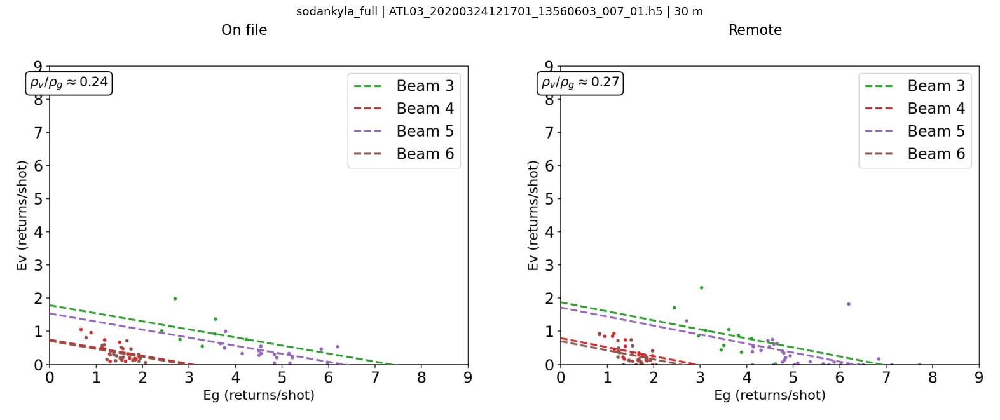


183: sodankyla_full | ATL03_20200411000258_02360705_007_01.h5
Failed to open ATL03 file for sodankyla_full file 183's beam 1.
Failed to open ATL03 file for sodankyla_full file 183's beam 2.
Beam 3 in sodankyla_full file 183 has no data after filtering.
Beam 4 in sodankyla_full file 183 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20200411000258_02360705_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,atmosphere_rejected,7925.0,16.0,0.0,0.0
3,gt2r,ok,30339.0,41.0,30.0,0.0
4,gt3l,ok,23298.0,270.0,23.0,20.0
5,gt3r,ok,94422.0,269.0,67.0,67.0


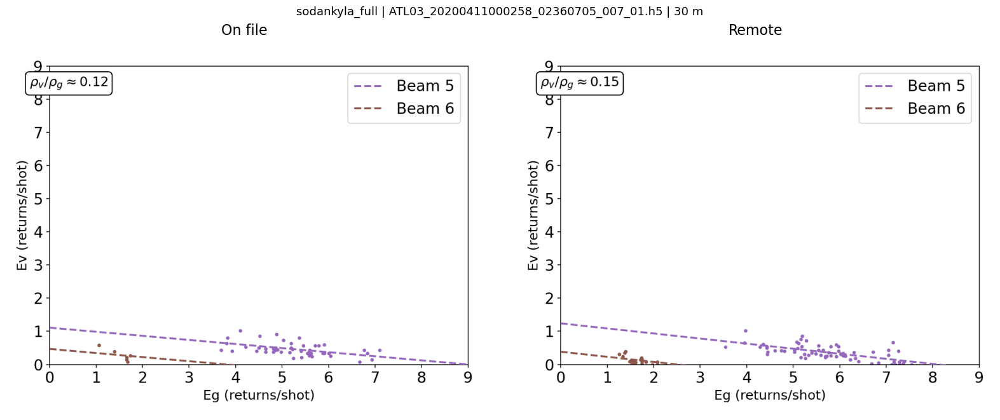


184: sodankyla_full | ATL03_20200422105308_04110703_007_01.h5
Beam 1 in sodankyla_full file 184 has no data after filtering.
Beam 2 in sodankyla_full file 184 has no data after filtering.
Beam 3 in sodankyla_full file 184 has no data after filtering.
Beam 4 in sodankyla_full file 184 has no data after filtering.
Nothing to rebin for sodankyla_full file 184's beam 5.
Nothing to rebin for sodankyla_full file 184's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20200422105308_04110703_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,58655.0,176.0,84.0,0.0
1,gt1r,ok,95653.0,266.0,97.0,0.0
2,gt2l,ok,63249.0,146.0,57.0,0.0
3,gt2r,ok,100723.0,270.0,59.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



185: sodankyla_full | ATL03_20200611210642_11810705_007_01.h5
Failed to open ATL03 file for sodankyla_full file 185's beam 1.
Failed to open ATL03 file for sodankyla_full file 185's beam 2.
Failed to open ATL03 file for sodankyla_full file 185's beam 3.
Failed to open ATL03 file for sodankyla_full file 185's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20200611210642_11810705_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,27580.0,270.0,240.0,237.0
1,gt1r,ok,8080.0,269.0,175.0,170.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


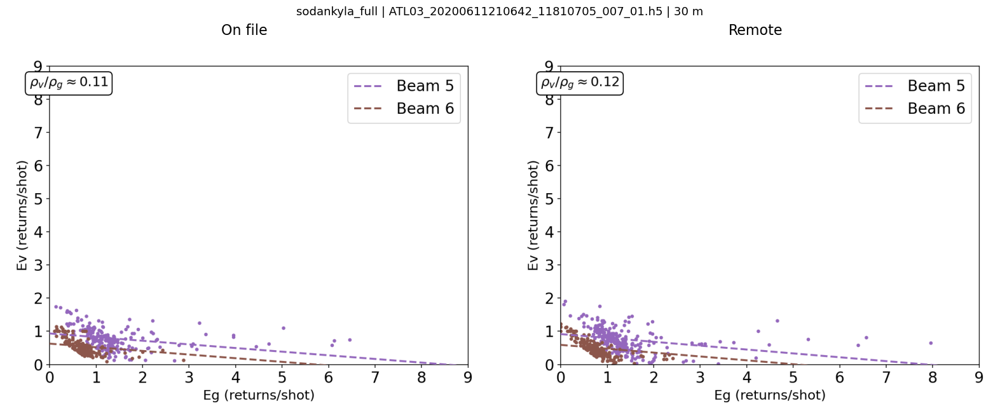


186: sodankyla_full | ATL03_20200623075651_13560703_007_01.h5
Nothing to rebin for sodankyla_full file 186's beam 1.
Nothing to rebin for sodankyla_full file 186's beam 2.
Failed to open ATL03 file for sodankyla_full file 186's beam 3.
Failed to open ATL03 file for sodankyla_full file 186's beam 4.
Failed to open ATL03 file for sodankyla_full file 186's beam 5.
Failed to open ATL03 file for sodankyla_full file 186's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20200623075651_13560703_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



187: sodankyla_full | ATL03_20200710194244_02360805_007_01.h5
Nothing to rebin for sodankyla_full file 187's beam 1.
Nothing to rebin for sodankyla_full file 187's beam 2.
Nothing to rebin for sodankyla_full file 187's beam 3.
Nothing to rebin for sodankyla_full file 187's beam 4.
Failed to open ATL03 file for sodankyla_full file 187's beam 5.
Failed to open ATL03 file for sodankyla_full file 187's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20200710194244_02360805_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



188: sodankyla_full | ATL03_20200722063254_04110803_007_01.h5
Failed to open ATL03 file for sodankyla_full file 188's beam 1.
Failed to open ATL03 file for sodankyla_full file 188's beam 2.
Failed to open ATL03 file for sodankyla_full file 188's beam 3.
Failed to open ATL03 file for sodankyla_full file 188's beam 4.
Nothing to rebin for sodankyla_full file 188's beam 5.
Nothing to rebin for sodankyla_full file 188's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20200722063254_04110803_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



189: sodankyla_full | ATL03_20200910164631_11810805_007_01.h5
Failed to open ATL03 file for sodankyla_full file 189's beam 1.
Failed to open ATL03 file for sodankyla_full file 189's beam 2.
Failed to open ATL03 file for sodankyla_full file 189's beam 3.
Failed to open ATL03 file for sodankyla_full file 189's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20200910164631_11810805_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,21066.0,270.0,243.0,233.0
1,gt1r,ok,6223.0,270.0,188.0,177.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


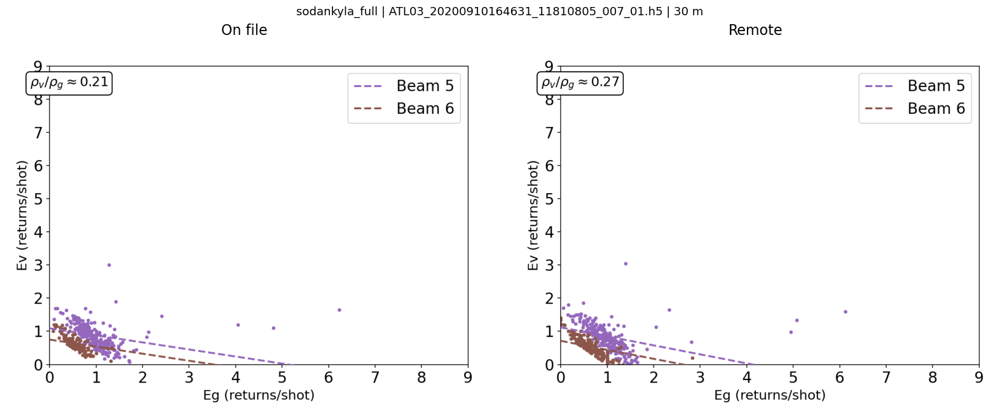


190: sodankyla_full | ATL03_20200922033639_13560803_007_01.h5
Nothing to rebin for sodankyla_full file 190's beam 1.
Nothing to rebin for sodankyla_full file 190's beam 2.
Failed to open ATL03 file for sodankyla_full file 190's beam 3.
Nothing to rebin for sodankyla_full file 190's beam 4.
Failed to open ATL03 file for sodankyla_full file 190's beam 5.
Failed to open ATL03 file for sodankyla_full file 190's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20200922033639_13560803_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



191: sodankyla_full | ATL03_20201009152232_02360905_007_01.h5
Nothing to rebin for sodankyla_full file 191's beam 1.
Failed to open ATL03 file for sodankyla_full file 191's beam 2.
Failed to open ATL03 file for sodankyla_full file 191's beam 3.
Failed to open ATL03 file for sodankyla_full file 191's beam 4.
Failed to open ATL03 file for sodankyla_full file 191's beam 5.
Failed to open ATL03 file for sodankyla_full file 191's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20201009152232_02360905_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



192: sodankyla_full | ATL03_20201021021240_04110903_007_01.h5
Failed to open ATL03 file for sodankyla_full file 192's beam 1.
Failed to open ATL03 file for sodankyla_full file 192's beam 2.
Beam 3 in sodankyla_full file 192 has no data after filtering.
Beam 4 in sodankyla_full file 192 has no data after filtering.
Beam 5 in sodankyla_full file 192 has no data after filtering.
Beam 6 in sodankyla_full file 192 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20201021021240_04110903_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,44340.0,270.0,102.0,0.0
1,gt1r,ok,10184.0,270.0,14.0,0.0
2,gt2l,ok,20197.0,206.0,36.0,0.0
3,gt2r,ok,6370.0,179.0,16.0,0.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


... (8 outputs left out)


197: sodankyla_full | ATL03_20210409064218_02361105_007_01.h5
Failed to open ATL03 file for sodankyla_full file 197's beam 1.
Failed to open ATL03 file for sodankyla_full file 197's beam 2.
Failed to open ATL03 file for sodankyla_full file 197's beam 3.
Failed to open ATL03 file for sodankyla_full file 197's beam 4.
Nothing to rebin for sodankyla_full file 197's beam 5.
Nothing to rebin for sodankyla_full file 197's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20210409064218_02361105_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



198: sodankyla_full | ATL03_20210420173227_04111103_007_01.h5
Beam 6 in sodankyla_full file 198 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20210420173227_04111103_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,16810,269,78,17
1,gt1r,ok,40004,270,100,24
2,gt2l,ok,17567,270,22,10
3,gt2r,ok,38040,269,53,33
4,gt3l,atmosphere_rejected,12424,64,0,0
5,gt3r,ok,29148,38,3,3


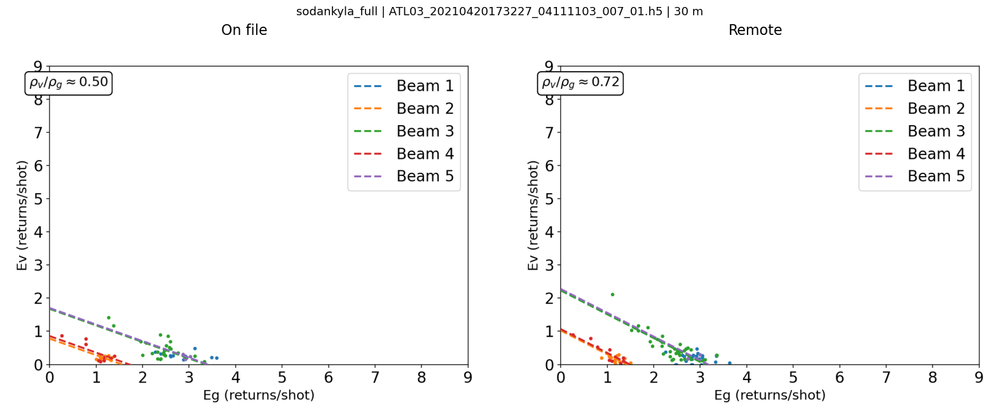


199: sodankyla_full | ATL03_20210610034606_11811105_007_01.h5
Failed to open ATL03 file for sodankyla_full file 199's beam 3.
Failed to open ATL03 file for sodankyla_full file 199's beam 4.
Failed to open ATL03 file for sodankyla_full file 199's beam 5.
Failed to open ATL03 file for sodankyla_full file 199's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20210610034606_11811105_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,15925.0,270.0,226.0,212.0
1,gt1r,ok,28851.0,270.0,247.0,229.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


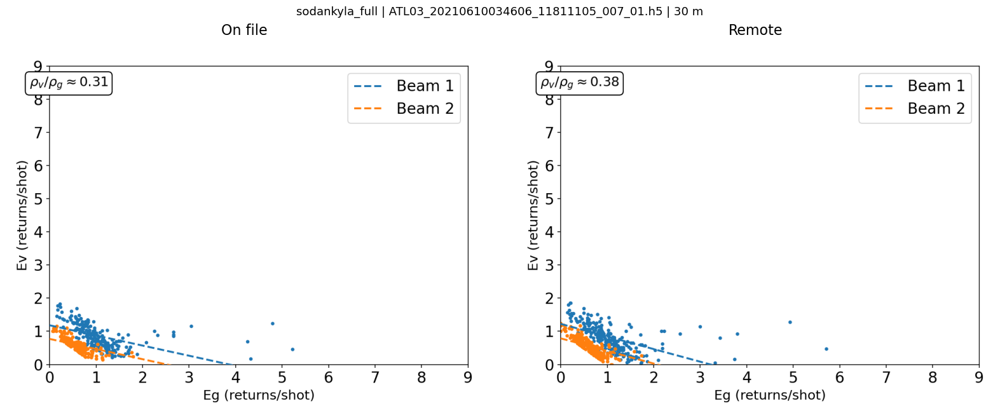


200: sodankyla_full | ATL03_20210621143613_13561103_007_01.h5
Failed to open ATL03 file for sodankyla_full file 200's beam 1.
Failed to open ATL03 file for sodankyla_full file 200's beam 2.
Failed to open ATL03 file for sodankyla_full file 200's beam 3.
Failed to open ATL03 file for sodankyla_full file 200's beam 4.
Failed to open ATL03 file for sodankyla_full file 200's beam 5.
Failed to open ATL03 file for sodankyla_full file 200's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20210621143613_13561103_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



201: sodankyla_full | ATL03_20210709022208_02361205_007_01.h5
Failed to open ATL03 file for sodankyla_full file 201's beam 1.
Failed to open ATL03 file for sodankyla_full file 201's beam 2.
sodankyla_full: 1 overpasses
  ATL03_20210709022208_02361205_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,8964.0,15.0,3.0,3.0
3,gt2r,ok,20177.0,43.0,40.0,40.0
4,gt3l,ok,12692.0,270.0,56.0,42.0
5,gt3r,ok,28827.0,269.0,130.0,97.0


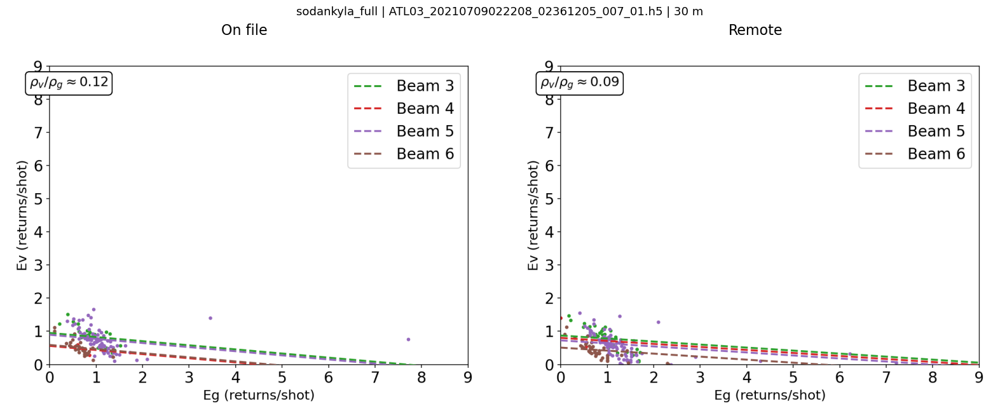


202: sodankyla_full | ATL03_20210720131217_04111203_007_01.h5
Beam 2 in sodankyla_full file 202 has no data after filtering.
Nothing to rebin for sodankyla_full file 202's beam 3.
Nothing to rebin for sodankyla_full file 202's beam 4.
Failed to open ATL03 file for sodankyla_full file 202's beam 5.
Failed to open ATL03 file for sodankyla_full file 202's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20210720131217_04111203_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,16403.0,132.0,8.0,0.0
1,gt1r,ok,40754.0,270.0,127.0,3.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


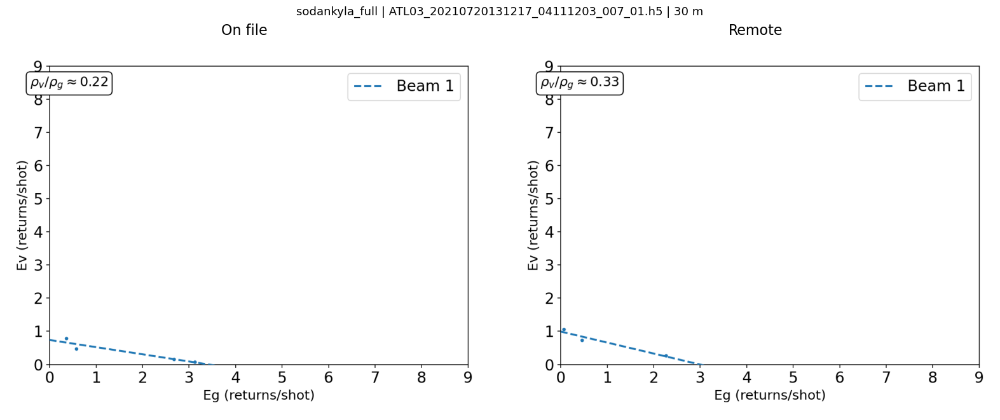


203: sodankyla_full | ATL03_20210908232601_11811205_007_01.h5
Failed to open ATL03 file for sodankyla_full file 203's beam 3.
Failed to open ATL03 file for sodankyla_full file 203's beam 4.
Failed to open ATL03 file for sodankyla_full file 203's beam 5.
Failed to open ATL03 file for sodankyla_full file 203's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20210908232601_11811205_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,4140.0,270.0,169.0,58.0
1,gt1r,ok,16381.0,270.0,249.0,90.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


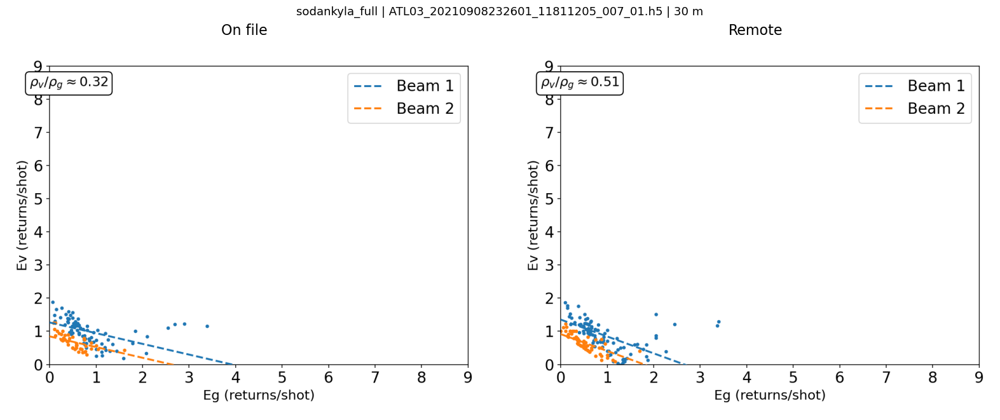


204: sodankyla_full | ATL03_20210920101609_13561203_007_01.h5
Failed to open ATL03 file for sodankyla_full file 204's beam 1.
Failed to open ATL03 file for sodankyla_full file 204's beam 2.
Nothing to rebin for sodankyla_full file 204's beam 3.
Nothing to rebin for sodankyla_full file 204's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20210920101609_13561203_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,15917.0,252.0,158.0,58.0
5,gt3r,ok,29807.0,270.0,196.0,86.0


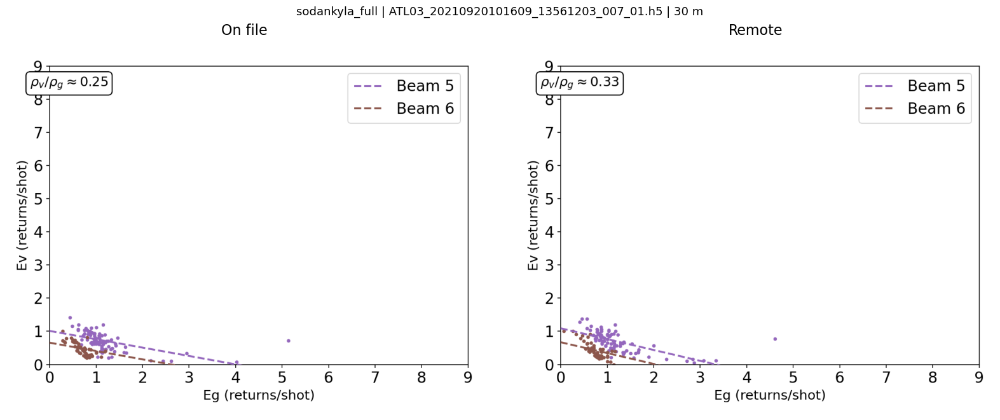


205: sodankyla_full | ATL03_20211007220207_02361305_007_01.h5
Beam 1 in sodankyla_full file 205 has no data after filtering.
Beam 2 in sodankyla_full file 205 has no data after filtering.
Nothing to rebin for sodankyla_full file 205's beam 3.
Nothing to rebin for sodankyla_full file 205's beam 4.
Failed to open ATL03 file for sodankyla_full file 205's beam 5.
Failed to open ATL03 file for sodankyla_full file 205's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20211007220207_02361305_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,54660.0,220.0,37.0,0.0
5,gt3r,ok,15204.0,187.0,2.0,0.0



206: sodankyla_full | ATL03_20211220055605_13561303_007_01.h5
Beam 5 in sodankyla_full file 206 has no data after filtering.
Beam 6 in sodankyla_full file 206 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20211220055605_13561303_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,49090,36,36,0
1,gt1r,ok,13888,61,61,0
2,gt2l,ok,80169,270,239,236
3,gt2r,ok,23999,270,209,202
4,gt3l,ok,97605,270,158,14
5,gt3r,ok,23970,269,171,13


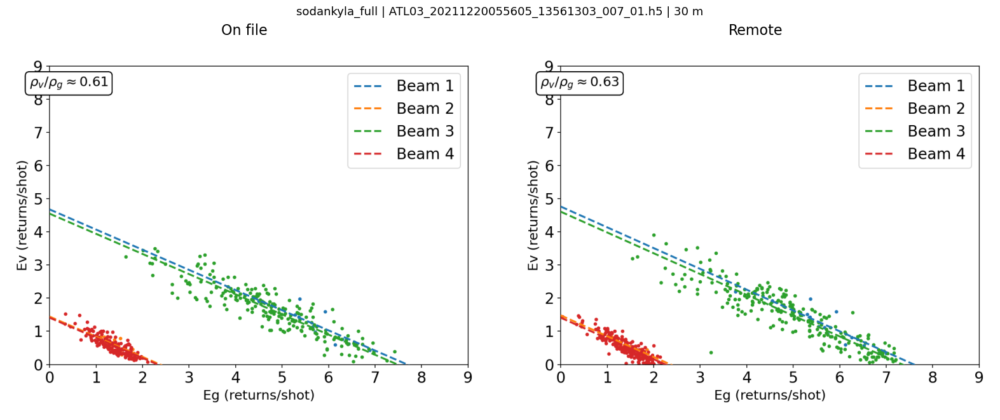


207: sodankyla_full | ATL03_20220106174200_02361405_007_01.h5
Nothing to rebin for sodankyla_full file 207's beam 1.
Failed to open ATL03 file for sodankyla_full file 207's beam 2.
Nothing to rebin for sodankyla_full file 207's beam 3.
Nothing to rebin for sodankyla_full file 207's beam 4.
Failed to open ATL03 file for sodankyla_full file 207's beam 5.
Failed to open ATL03 file for sodankyla_full file 207's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20220106174200_02361405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



208: sodankyla_full | ATL03_20220118043209_04111403_007_01.h5
Failed to open ATL03 file for sodankyla_full file 208's beam 1.
Failed to open ATL03 file for sodankyla_full file 208's beam 2.
Nothing to rebin for sodankyla_full file 208's beam 3.
Nothing to rebin for sodankyla_full file 208's beam 4.
Beam 5 in sodankyla_full file 208 has no data after filtering.
Beam 6 in sodankyla_full file 208 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20220118043209_04111403_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,48548.0,270.0,99.0,0.0
1,gt1r,ok,11503.0,270.0,61.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



209: sodankyla_full | ATL03_20220309144548_11811405_007_01.h5
Failed to open ATL03 file for sodankyla_full file 209's beam 1.
Failed to open ATL03 file for sodankyla_full file 209's beam 2.
Failed to open ATL03 file for sodankyla_full file 209's beam 3.
Failed to open ATL03 file for sodankyla_full file 209's beam 4.
Nothing to rebin for sodankyla_full file 209's beam 5.
Nothing to rebin for sodankyla_full file 209's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20220309144548_11811405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



210: sodankyla_full | ATL03_20220321013557_13561403_007_01.h5
Nothing to rebin for sodankyla_full file 210's beam 1.
Failed to open ATL03 file for sodankyla_full file 210's beam 2.
Nothing to rebin for sodankyla_full file 210's beam 3.
Failed to open ATL03 file for sodankyla_full file 210's beam 4.
Failed to open ATL03 file for sodankyla_full file 210's beam 5.
Failed to open ATL03 file for sodankyla_full file 210's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20220321013557_13561403_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



211: sodankyla_full | ATL03_20220419001154_04111503_007_01.h5
Failed to open ATL03 file for sodankyla_full file 211's beam 1.
Failed to open ATL03 file for sodankyla_full file 211's beam 2.
Nothing to rebin for sodankyla_full file 211's beam 3.
Nothing to rebin for sodankyla_full file 211's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20220419001154_04111503_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,78986.0,270.0,116.0,113.0
1,gt1r,ok,17997.0,270.0,103.0,99.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


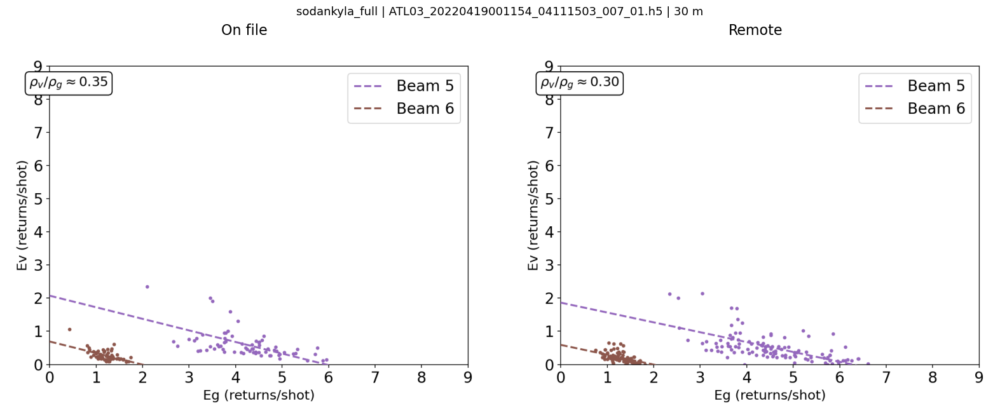


212: sodankyla_full | ATL03_20220608102541_11811505_007_01.h5
Nothing to rebin for sodankyla_full file 212's beam 1.
Nothing to rebin for sodankyla_full file 212's beam 2.
sodankyla_full: 1 overpasses
  ATL03_20220608102541_11811505_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,46617.0,270.0,109.0,62.0
1,gt1r,ok,25514.0,249.0,112.0,58.0
2,gt2l,ok,53998.0,265.0,138.0,106.0
3,gt2r,ok,21037.0,176.0,109.0,89.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


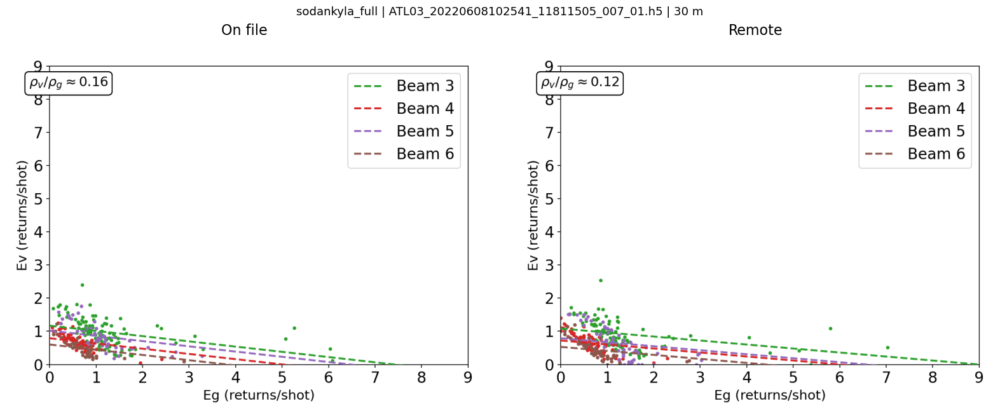


213: sodankyla_full | ATL03_20220707090150_02361605_007_01.h5
Failed to open ATL03 file for sodankyla_full file 213's beam 1.
Failed to open ATL03 file for sodankyla_full file 213's beam 2.
Failed to open ATL03 file for sodankyla_full file 213's beam 3.
Failed to open ATL03 file for sodankyla_full file 213's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20220707090150_02361605_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,26342.0,133.0,66.0,47.0
5,gt3r,ok,68434.0,190.0,66.0,55.0


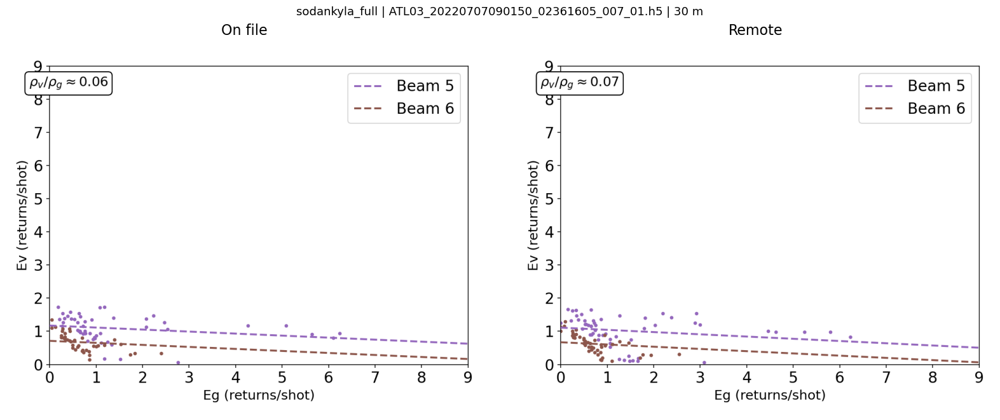


214: sodankyla_full | ATL03_20220718195157_04111603_007_01.h5
Beam 1 in sodankyla_full file 214 has no data after filtering.
Beam 2 in sodankyla_full file 214 has no data after filtering.
Nothing to rebin for sodankyla_full file 214's beam 3.
Nothing to rebin for sodankyla_full file 214's beam 4.
Failed to open ATL03 file for sodankyla_full file 214's beam 5.
Failed to open ATL03 file for sodankyla_full file 214's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20220718195157_04111603_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



215: sodankyla_full | ATL03_20220907060539_11811605_007_01.h5
Nothing to rebin for sodankyla_full file 215's beam 1.
Nothing to rebin for sodankyla_full file 215's beam 2.
Nothing to rebin for sodankyla_full file 215's beam 3.
Nothing to rebin for sodankyla_full file 215's beam 4.
Failed to open ATL03 file for sodankyla_full file 215's beam 5.
Failed to open ATL03 file for sodankyla_full file 215's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20220907060539_11811605_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



216: sodankyla_full | ATL03_20220918165545_13561603_007_01.h5
Failed to open ATL03 file for sodankyla_full file 216's beam 1.
Failed to open ATL03 file for sodankyla_full file 216's beam 2.
Failed to open ATL03 file for sodankyla_full file 216's beam 3.
Failed to open ATL03 file for sodankyla_full file 216's beam 4.
Nothing to rebin for sodankyla_full file 216's beam 5.
Failed to open ATL03 file for sodankyla_full file 216's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20220918165545_13561603_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (10 outputs left out)


222: sodankyla_full | ATL03_20230307212510_11811805_007_01.h5
Failed to open ATL03 file for sodankyla_full file 222's beam 1.
Failed to open ATL03 file for sodankyla_full file 222's beam 2.
Failed to open ATL03 file for sodankyla_full file 222's beam 3.
Failed to open ATL03 file for sodankyla_full file 222's beam 4.
Beam 5 in sodankyla_full file 222 has no data after filtering.
Beam 6 in sodankyla_full file 222 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20230307212510_11811805_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,71259.0,270.0,195.0,0.0
1,gt1r,ok,17215.0,270.0,158.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



223: sodankyla_full | ATL03_20230319081525_13561803_007_01.h5
Nothing to rebin for sodankyla_full file 223's beam 3.
Nothing to rebin for sodankyla_full file 223's beam 4.
Failed to open ATL03 file for sodankyla_full file 223's beam 5.
Failed to open ATL03 file for sodankyla_full file 223's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230319081525_13561803_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,154879.0,270.0,196.0,193.0
5,gt3r,ok,68749.0,270.0,99.0,99.0


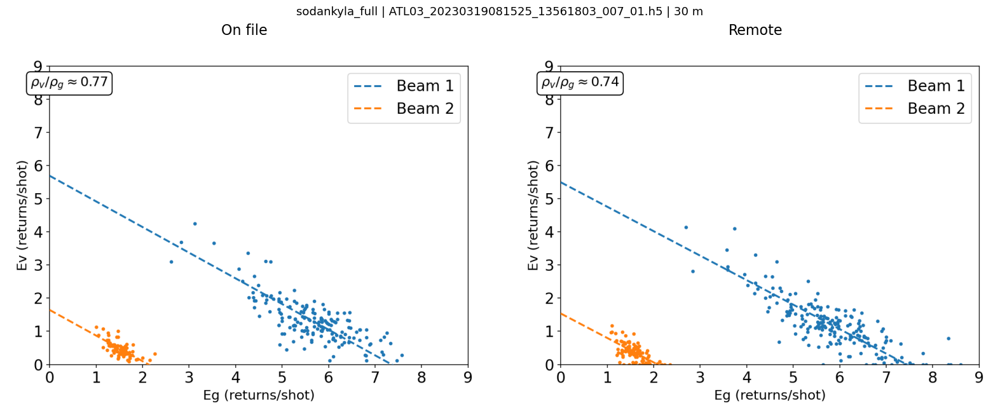


224: sodankyla_full | ATL03_20230405200119_02361905_007_01.h5
Beam 1 in sodankyla_full file 224 has no data after filtering.
Beam 2 in sodankyla_full file 224 has no data after filtering.
Failed to open ATL03 file for sodankyla_full file 224's beam 3.
Failed to open ATL03 file for sodankyla_full file 224's beam 4.
Failed to open ATL03 file for sodankyla_full file 224's beam 5.
Failed to open ATL03 file for sodankyla_full file 224's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230405200119_02361905_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,ok,44251.0,270.0,70.0,0.0
5,gt3r,ok,11174.0,269.0,27.0,0.0



225: sodankyla_full | ATL03_20230417065118_04111903_007_01.h5
Failed to open ATL03 file for sodankyla_full file 225's beam 1.
Failed to open ATL03 file for sodankyla_full file 225's beam 2.
Nothing to rebin for sodankyla_full file 225's beam 3.
Nothing to rebin for sodankyla_full file 225's beam 4.
Nothing to rebin for sodankyla_full file 225's beam 5.
Nothing to rebin for sodankyla_full file 225's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230417065118_04111903_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



226: sodankyla_full | ATL03_20230606170434_11811905_007_01.h5
Failed to open ATL03 file for sodankyla_full file 226's beam 1.
Failed to open ATL03 file for sodankyla_full file 226's beam 2.
Nothing to rebin for sodankyla_full file 226's beam 3.
Nothing to rebin for sodankyla_full file 226's beam 4.
Nothing to rebin for sodankyla_full file 226's beam 5.
Nothing to rebin for sodankyla_full file 226's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230606170434_11811905_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08


... (2 outputs left out)


228: sodankyla_full | ATL03_20230705154028_02362005_007_01.h5
Nothing to rebin for sodankyla_full file 228's beam 1.
Nothing to rebin for sodankyla_full file 228's beam 2.
Beam 3 in sodankyla_full file 228 has no data after filtering.
Beam 4 in sodankyla_full file 228 has no data after filtering.
Failed to open ATL03 file for sodankyla_full file 228's beam 5.
Failed to open ATL03 file for sodankyla_full file 228's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230705154028_02362005_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,37313.0,270.0,10.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



229: sodankyla_full | ATL03_20230717023029_04112003_007_01.h5
Failed to open ATL03 file for sodankyla_full file 229's beam 1.
Failed to open ATL03 file for sodankyla_full file 229's beam 2.
Failed to open ATL03 file for sodankyla_full file 229's beam 3.
Failed to open ATL03 file for sodankyla_full file 229's beam 4.
sodankyla_full: 1 overpasses
  ATL03_20230717023029_04112003_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,35845.0,270.0,36.0,7.0
1,gt1r,ok,6360.0,103.0,22.0,6.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


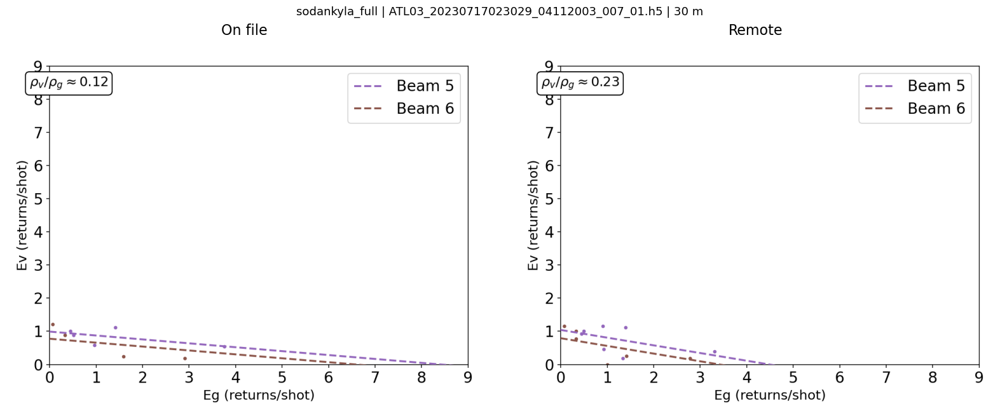


230: sodankyla_full | ATL03_20230905124352_11812005_007_01.h5
Failed to open ATL03 file for sodankyla_full file 230's beam 1.
Failed to open ATL03 file for sodankyla_full file 230's beam 2.
Failed to open ATL03 file for sodankyla_full file 230's beam 3.
Failed to open ATL03 file for sodankyla_full file 230's beam 4.
Nothing to rebin for sodankyla_full file 230's beam 5.
Nothing to rebin for sodankyla_full file 230's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230905124352_11812005_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,atmosphere_rejected,728.0,0.0,0.0,0.0
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN



231: sodankyla_full | ATL03_20230916233402_13562003_007_01.h5
Nothing to rebin for sodankyla_full file 231's beam 1.
Nothing to rebin for sodankyla_full file 231's beam 2.
Nothing to rebin for sodankyla_full file 231's beam 3.
Failed to open ATL03 file for sodankyla_full file 231's beam 4.
Failed to open ATL03 file for sodankyla_full file 231's beam 5.
Failed to open ATL03 file for sodankyla_full file 231's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20230916233402_13562003_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



232: sodankyla_full | ATL03_20231004111956_02362105_007_01.h5
Nothing to rebin for sodankyla_full file 232's beam 1.
Nothing to rebin for sodankyla_full file 232's beam 2.
Nothing to rebin for sodankyla_full file 232's beam 3.
Nothing to rebin for sodankyla_full file 232's beam 4.
Failed to open ATL03 file for sodankyla_full file 232's beam 5.
Failed to open ATL03 file for sodankyla_full file 232's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20231004111956_02362105_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,atmosphere_rejected,59544.0,208.0,0.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


... (10 outputs left out)


238: sodankyla_full | ATL03_20240312150122_12952203_007_01.h5
Nothing to rebin for sodankyla_full file 238's beam 1.
Nothing to rebin for sodankyla_full file 238's beam 2.
Nothing to rebin for sodankyla_full file 238's beam 3.
Nothing to rebin for sodankyla_full file 238's beam 4.
Nothing to rebin for sodankyla_full file 238's beam 5.
Nothing to rebin for sodankyla_full file 238's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20240312150122_12952203_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



239: sodankyla_full | ATL03_20240316145300_13562203_007_01.h5
sodankyla_full: 1 overpasses
  ATL03_20240316145300_13562203_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,33401,269,71,71
1,gt1r,ok,99062,270,171,167
2,gt2l,ok,35887,270,80,80
3,gt2r,ok,84832,270,130,130
4,gt3l,ok,37626,270,65,65
5,gt3r,ok,112391,270,93,93


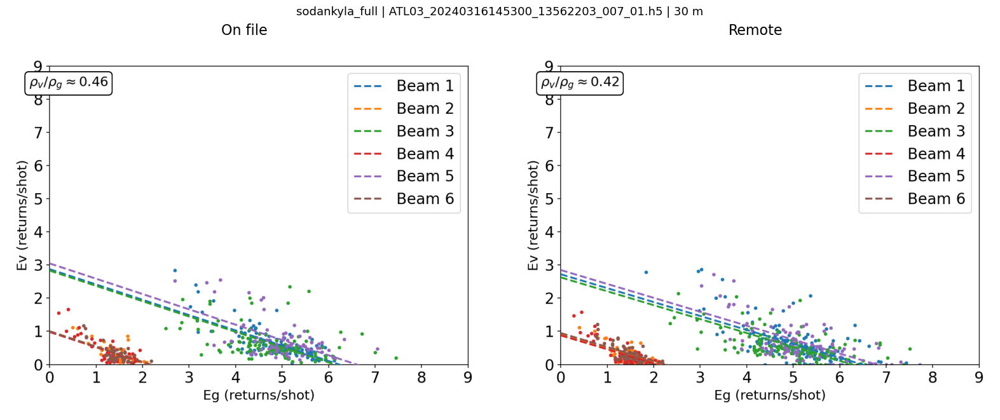


240: sodankyla_full | ATL03_20240403023858_02362305_007_01.h5
sodankyla_full: 1 overpasses
  ATL03_20240403023858_02362305_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,21902,270,72,72
1,gt1r,ok,85760,269,120,116
2,gt2l,ok,20396,269,56,56
3,gt2r,ok,68794,270,115,111
4,gt3l,ok,20781,270,89,89
5,gt3r,ok,84751,270,173,173


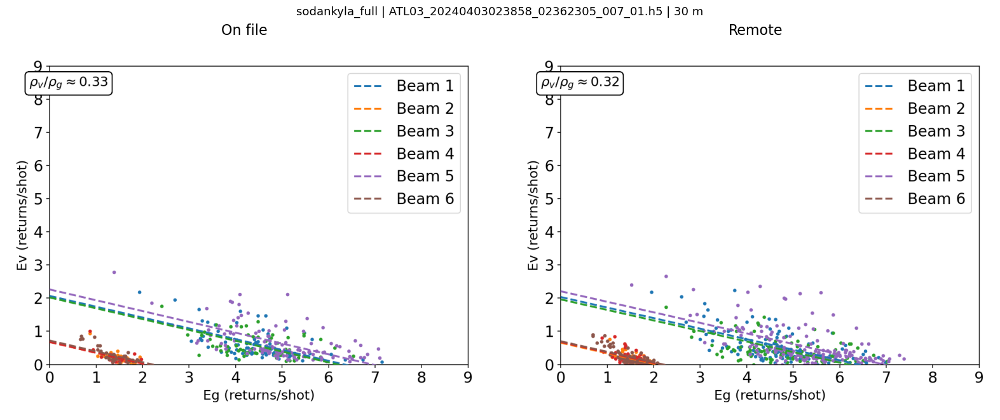


241: sodankyla_full | ATL03_20240407023039_02972305_007_01.h5
sodankyla_full: 1 overpasses
  ATL03_20240407023039_02972305_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,23213,270,120,116
1,gt1r,ok,91947,270,162,135
2,gt2l,ok,21604,270,93,93
3,gt2r,ok,72418,270,136,136
4,gt3l,ok,21726,269,137,137
5,gt3r,ok,88918,270,216,213


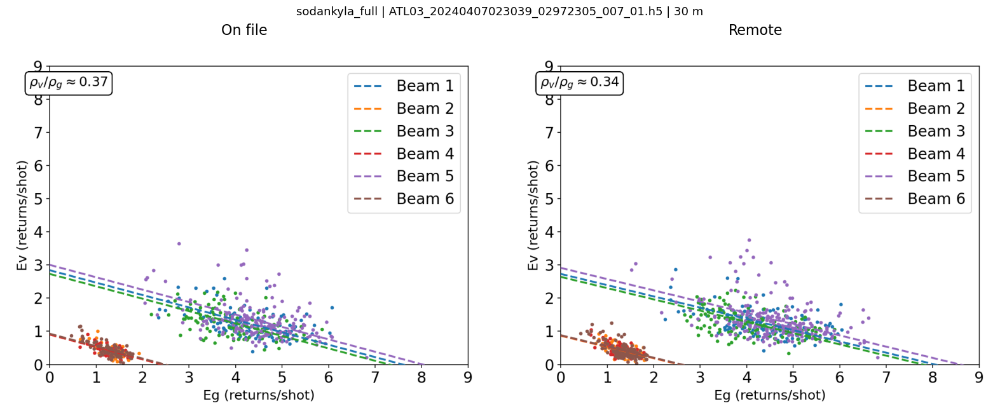


242: sodankyla_full | ATL03_20240414132901_04112303_007_01.h5
Nothing to rebin for sodankyla_full file 242's beam 3.
Nothing to rebin for sodankyla_full file 242's beam 4.
Failed to open ATL03 file for sodankyla_full file 242's beam 5.
Failed to open ATL03 file for sodankyla_full file 242's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20240414132901_04112303_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,86481.0,270.0,41.0,41.0
1,gt1r,ok,157535.0,269.0,6.0,6.0
2,gt2l,atmosphere_rejected,26102.0,1.0,1.0,0.0
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


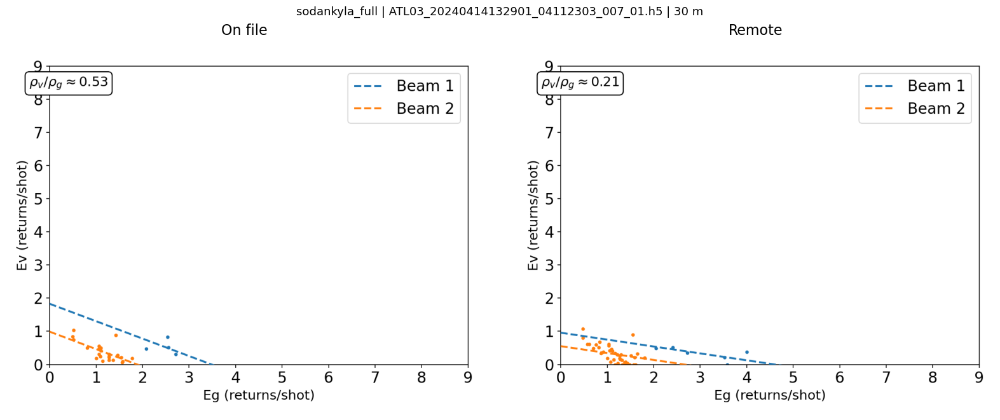


243: sodankyla_full | ATL03_20240502011506_06782305_007_01.h5
Nothing to rebin for sodankyla_full file 243's beam 1.
Nothing to rebin for sodankyla_full file 243's beam 2.
Nothing to rebin for sodankyla_full file 243's beam 3.
Nothing to rebin for sodankyla_full file 243's beam 4.
Nothing to rebin for sodankyla_full file 243's beam 5.
Nothing to rebin for sodankyla_full file 243's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20240502011506_06782305_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



244: sodankyla_full | ATL03_20240702221844_02362405_007_01.h5
Nothing to rebin for sodankyla_full file 244's beam 1.
Nothing to rebin for sodankyla_full file 244's beam 2.
Nothing to rebin for sodankyla_full file 244's beam 3.
Nothing to rebin for sodankyla_full file 244's beam 4.
Failed to open ATL03 file for sodankyla_full file 244's beam 5.
Failed to open ATL03 file for sodankyla_full file 244's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20240702221844_02362405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



245: sodankyla_full | ATL03_20240714090839_04112403_007_01.h5
Failed to open ATL03 file for sodankyla_full file 245's beam 1.
Failed to open ATL03 file for sodankyla_full file 245's beam 2.
sodankyla_full: 1 overpasses
  ATL03_20240714090839_04112403_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,56812.0,270.0,168.0,161.0
1,gt1r,ok,28170.0,270.0,82.0,82.0
2,gt2l,ok,62100.0,205.0,95.0,91.0
3,gt2r,ok,28324.0,177.0,51.0,51.0
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


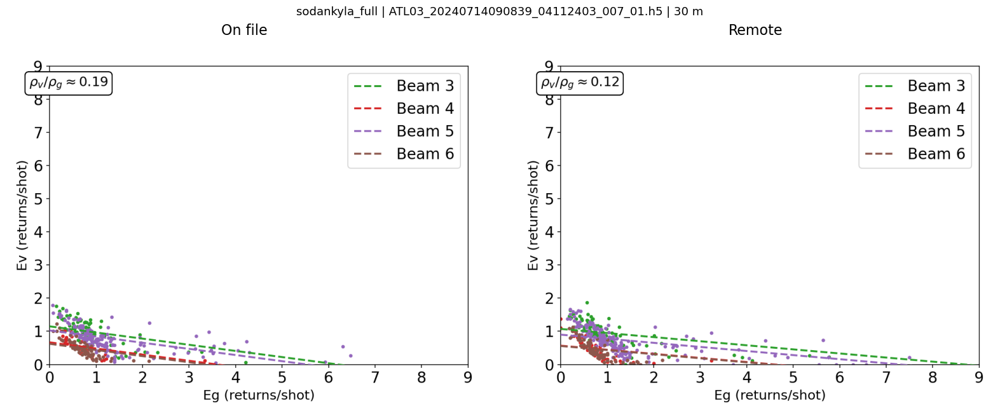


246: sodankyla_full | ATL03_20240902192222_11812405_007_01.h5
Failed to open ATL03 file for sodankyla_full file 246's beam 1.
Failed to open ATL03 file for sodankyla_full file 246's beam 2.
Nothing to rebin for sodankyla_full file 246's beam 3.
Failed to open ATL03 file for sodankyla_full file 246's beam 4.
Nothing to rebin for sodankyla_full file 246's beam 5.
Nothing to rebin for sodankyla_full file 246's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20240902192222_11812405_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



247: sodankyla_full | ATL03_20240914061230_13562403_007_01.h5
Nothing to rebin for sodankyla_full file 247's beam 1.
Nothing to rebin for sodankyla_full file 247's beam 2.
Failed to open ATL03 file for sodankyla_full file 247's beam 3.
Failed to open ATL03 file for sodankyla_full file 247's beam 4.
Failed to open ATL03 file for sodankyla_full file 247's beam 5.
Failed to open ATL03 file for sodankyla_full file 247's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20240914061230_13562403_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



248: sodankyla_full | ATL03_20241001175816_02362505_007_01.h5
Beam 1 in sodankyla_full file 248 has no data after filtering.


/scratch/s1803229/.conda/envs/snow_env/lib/python3.11/site-packages/scipy/interpolate/_interpolate.py:701: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


... (4 outputs left out)


249: sodankyla_full | ATL03_20241013044838_04112503_007_01.h5
Failed to open ATL03 file for sodankyla_full file 249's beam 1.
Failed to open ATL03 file for sodankyla_full file 249's beam 2.
Failed to open ATL03 file for sodankyla_full file 249's beam 3.
Failed to open ATL03 file for sodankyla_full file 249's beam 4.
Nothing to rebin for sodankyla_full file 249's beam 5.
Failed to open ATL03 file for sodankyla_full file 249's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20241013044838_04112503_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



250: sodankyla_full | ATL03_20241214015156_13562503_007_01.h5
Beam 1 in sodankyla_full file 250 has no data after filtering.
Beam 2 in sodankyla_full file 250 has no data after filtering.
Nothing to rebin for sodankyla_full file 250's beam 5.
Nothing to rebin for sodankyla_full file 250's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20241214015156_13562503_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,no_atl08,NaN,NaN,NaN,NaN
1,gt1r,no_atl08,NaN,NaN,NaN,NaN
2,gt2l,ok,43485.0,270.0,120.0,110.0
3,gt2r,ok,13320.0,270.0,27.0,27.0
4,gt3l,ok,57504.0,270.0,36.0,0.0
5,gt3r,ok,14484.0,270.0,16.0,0.0


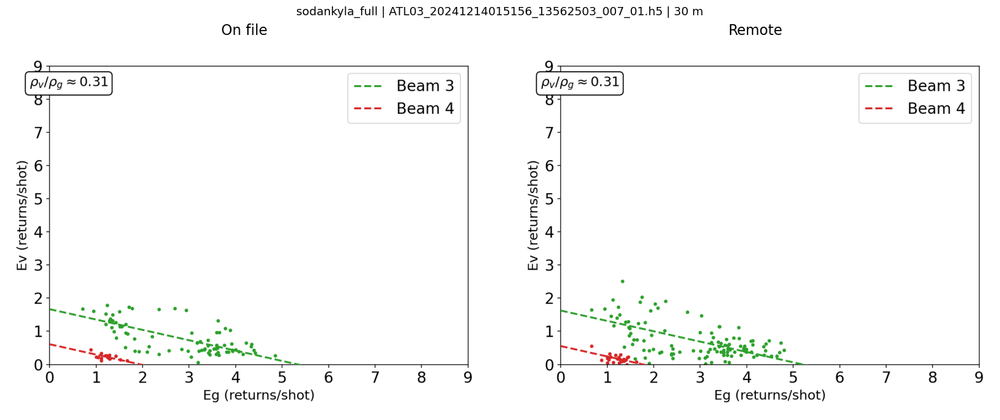


251: sodankyla_full | ATL03_20241231133747_02362605_007_01.h5


/scratch/s1803229/.conda/envs/snow_env/lib/python3.11/site-packages/scipy/interpolate/_interpolate.py:701: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


Beam 1 in sodankyla_full file 251 has no data after filtering.
Beam 2 in sodankyla_full file 251 has no data after filtering.
Nothing to rebin for sodankyla_full file 251's beam 3.
Nothing to rebin for sodankyla_full file 251's beam 4.
Failed to open ATL03 file for sodankyla_full file 251's beam 5.
Failed to open ATL03 file for sodankyla_full file 251's beam 6.
sodankyla_full: 1 overpasses
  ATL03_20241231133747_02362605_007_01.h5


,beam,status
0,gt1l,no_atl08
1,gt1r,no_atl08
2,gt2l,no_atl08
3,gt2r,no_atl08
4,gt3l,no_atl08
5,gt3r,no_atl08



252: sodankyla_full | ATL03_20250112002824_04112603_007_01.h5
Failed to open ATL03 file for sodankyla_full file 252's beam 1.
Failed to open ATL03 file for sodankyla_full file 252's beam 2.
Nothing to rebin for sodankyla_full file 252's beam 3.
Nothing to rebin for sodankyla_full file 252's beam 4.
Beam 5 in sodankyla_full file 252 has no data after filtering.
Beam 6 in sodankyla_full file 252 has no data after filtering.
sodankyla_full: 1 overpasses
  ATL03_20250112002824_04112603_007_01.h5


,beam,status,photons,bins,matched_bins,accepted_bins
0,gt1l,ok,39659.0,270.0,129.0,0.0
1,gt1r,ok,9642.0,270.0,49.0,0.0
2,gt2l,no_atl08,NaN,NaN,NaN,NaN
3,gt2r,no_atl08,NaN,NaN,NaN,NaN
4,gt3l,no_atl08,NaN,NaN,NaN,NaN
5,gt3r,no_atl08,NaN,NaN,NaN,NaN


,pair,site,resource,pipeline,status
0,0,delta_junction,ATL03_20181105235511_05860103_007_01.h5,On file,Plotted
1,0,delta_junction,ATL03_20181105235511_05860103_007_01.h5,Remote,Plotted
2,1,delta_junction,ATL03_20181115115748_07310105_007_01.h5,On file,No usable fit / no plot
3,1,delta_junction,ATL03_20181115115748_07310105_007_01.h5,Remote,No usable fit / no plot
4,2,delta_junction,ATL03_20190204193503_05860203_007_01.h5,On file,No usable fit / no plot
...,...,...,...,...,...
501,250,sodankyla_full,ATL03_20241214015156_13562503_007_01.h5,Remote,Plotted
502,251,sodankyla_full,ATL03_20241231133747_02362605_007_01.h5,On file,No usable fit / no plot
503,251,sodankyla_full,ATL03_20241231133747_02362605_007_01.h5,Remote,No usable fit / no plot
504,252,sodankyla_full,ATL03_20250112002824_04112603_007_01.h5,On file,No usable fit / no plot


In [4]:
chosen = pairs if PAIR_INDICES is None else pairs.loc[PAIR_INDICES]
if MAX_OVERPASSES is not None:
    chosen = chosen.head(MAX_OVERPASSES)
results, status = {}, []
for index, row in chosen.iterrows():
    print(f"\n{index}: {row.site} | {row.resource}", flush=True)
    run_cfg = deepcopy(cfg)
    run_cfg["parallel_blocks"]["altitude"] = float(row.altitude)
    coords = (float(row.longitude), float(row.latitude))
    west, south, east, north = local.make_box(
        coords, ROI_HALF_KM, ROI_HALF_KM).total_bounds
    site_table = pd.DataFrame([dict(
        site_id=row.site, west=west, south=south, east=east, north=north,
        longitude=coords[0], latitude=coords[1], altitude=float(row.altitude))])
    start = row.date.strftime("%Y-%m-%dT00:00:00Z")
    end = (row.date + pd.Timedelta(days=1)).strftime("%Y-%m-%dT00:00:00Z")

    def run_local():
        return local.pvpg_parallel(
            str(row.atl03.parent) + "/", str(row.atl03), str(row.atl08),
            deepcopy(run_cfg), coords=coords, file_index=index, graph_detail=1)

    def run_remote():
        return list(remote.run_sites(
            site_table, deepcopy(run_cfg), start, end,
            resources=[row.resource], max_resources=None,
            provider=provider, graph_detail=1))

    images, notes = [], []
    for label, call in [("On file", run_local), ("Remote", run_remote)]:
        # Keep stochastic outlier removal reproducible on repeated runs.
        np.random.seed(0)
        try:
            result, fig = capture_plot(call)
            results[(index, label)] = result
            note = "Plotted" if fig is not None else "No usable fit / no plot"
            images.append(plot_image(fig) if fig is not None else None)
            if label == "Remote":
                for run in result:
                    display(run.diagnostics)
        except Exception as exc:
            note = f"ERROR: {type(exc).__name__}: {exc}"
            images.append(None)
            print(f"{label}: {note}")
        notes.append(note)
        status.append(dict(pair=index, site=row.site, resource=row.resource,
                           pipeline=label, status=note))

    available = [
        (label, pixels)
        for label, pixels in zip(["On file", "Remote"], images)
        if pixels is not None
    ]
    if available:
        fig, axes = plt.subplots(
            1, len(available),
            figsize=(8 * len(available), 6.5),
            layout="constrained",
            squeeze=False,
        )
        for ax, (label, pixels) in zip(axes.ravel(), available):
            ax.set_title(label, fontsize=16)
            ax.axis("off")
            ax.imshow(pixels)
        fig.suptitle(
            f"{row.site} | {row.resource} | {LENGTH_M} m", fontsize=13
        )
        plt.show()

status = pd.DataFrame(status)
display(status)